## Checking automatic annotation and clustering

In [1]:
import os
os.chdir("/sas/sara/scRNAseq/mouse_u1/clean_code/")

from  global_variables_mouse import * 

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:63: UserWarning: Since v1.0.0, scvi-tools no longer uses a random seed by default. Run `scvi.settings.seed = 0` to reproduce results from previous versions.
  self.seed = seed
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scvi/_settings.py:70: UserWarning: Setting `dl_pin_memory_gpu_training` is deprecated in v1.0 and will be removed in v1.1. Please pass in `pin_memory` to the data loaders instead.
  self.dl_pin_memory_gpu_training = (
2025-11-28 11:17:15.873640: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-28 11:17:15.873681: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-28 11:17:15.873715:

In [2]:
%matplotlib inline

plt.rcParams['figure.dpi'] = 100

sns.set_theme(context='notebook', style="white", palette=spectrum)

In [3]:
from sklearn.datasets import make_blobs
import colorcet as cc

blobs, labels = make_blobs(n_samples=1000, centers=25, center_box=(-100, 100))
cluster_colors = sns.color_palette(cc.glasbey_light, n_colors=25,as_cmap=True)
distinctipy = ['#4d51f9', '#4af85e', '#f1634e', '#5ad8fd', '#567562', '#ffe94c', '#ee74fc', '#b1ac99', '#a649bc', '#4e97bd', '#b0ff94', '#9f9afd', '#fbc0c7', '#94c64b', '#a14c4e']

In [4]:
save_dir='/sas/sara/scRNAseq/pendas/'

adata = sc.read_h5ad(save_dir+"/manually_annotated_adata_label8.h5ad")

adata


AnnData object with n_obs × n_vars = 33486 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi'
    var: 'gene_ids-0', 'feature_types-0', 'genome-0', 'mt-0', 'rb-0', 'n_cells-0-0', 'n_cells_by_counts-0-0', 'mean_counts-0-0', 'pct_dropout_by_counts-0-0', 'total_counts-0-0', 'log1p_mean_counts-0-0', 'log1p_total_counts-

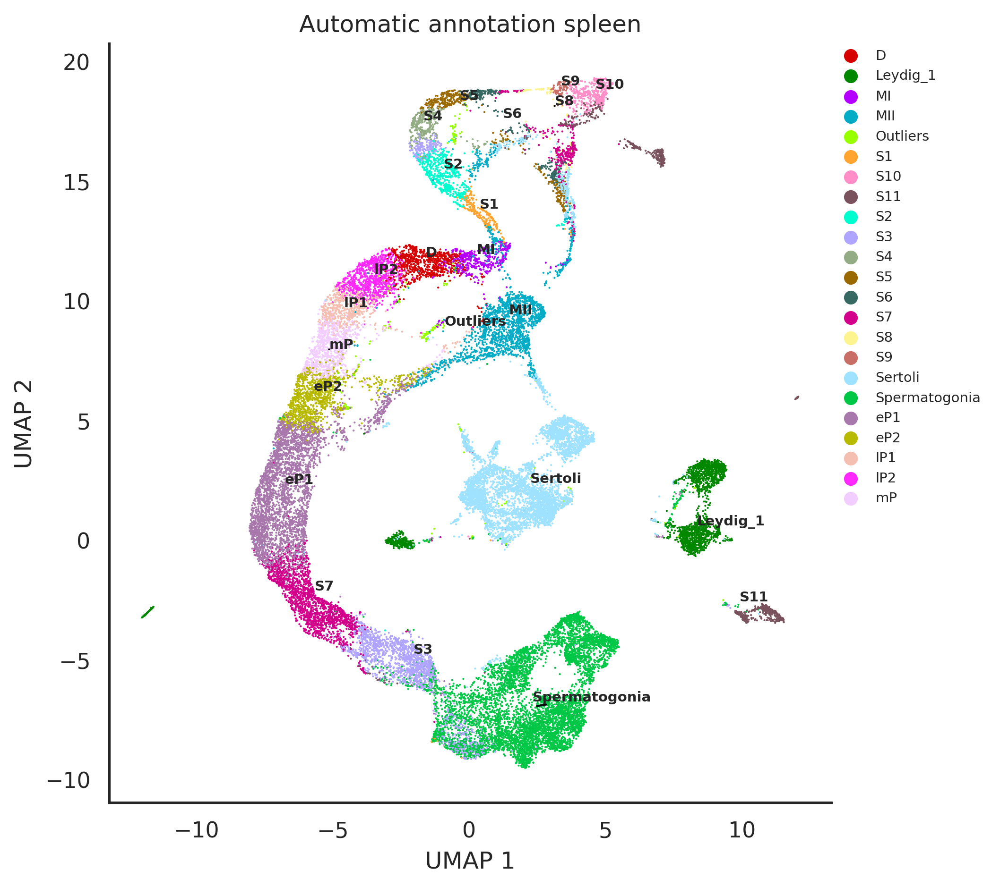

In [5]:
from adjustText import adjust_text

#adata_full.obs_names_make_unique()

def gen_mpl_labels(
    adata, groupby, exclude=(), ax=None, adjust_kwargs=None, text_kwargs=None
):
    if adjust_kwargs is None:
        adjust_kwargs = {"text_from_points": False, "force_text":10}
    if text_kwargs is None:
        text_kwargs = {}

    medians = {}

    for g, g_idx in adata.obs.groupby(groupby).groups.items():
        if g in exclude:
            continue
        medians[g] = np.median(adata[g_idx].obsm["X_umap"], axis=0)

    if ax is None:
        texts = [
            plt.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()
        ]
    else:
        texts = [ax.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()]

    adjust_text(texts, **adjust_kwargs)

with plt.rc_context({"figure.figsize": (7, 6), "figure.dpi": 300, "figure.frameon": False}):
    #ax = sc.pl.umap(adata_full, color="C_scANVI", show=False, legend_loc=None, frameon=False)
    plot = sns.scatterplot(x=adata.obsm["X_umap"][:,0], y=adata.obsm["X_umap"][:,1],hue =adata.obs["celltype_scanvi"],palette= cluster_colors[:len(adata.obs["celltype_scanvi"].unique())],marker='.',s=4,linewidth=0)
    sns.despine()
    legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False,fontsize=7)
    gen_mpl_labels(
        adata,
        "celltype_scanvi",
        exclude=("None",),  # This was before we had the `nan` behaviour
        ax=plot,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=7,weight='bold'),
    )
    fig = plot.get_figure()
    fig.tight_layout()
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2');
    plt.title("Automatic annotation spleen" )
    plt.show()

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


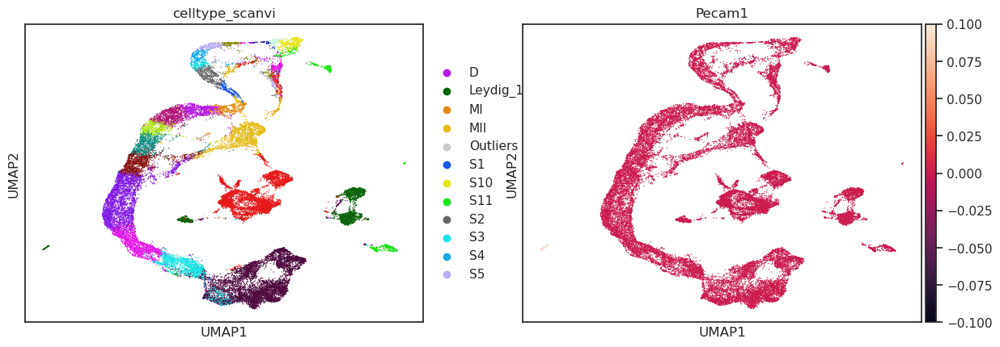

In [6]:
sc.pl.umap(adata,color=["celltype_scanvi","Pecam1"],vmax="p95")

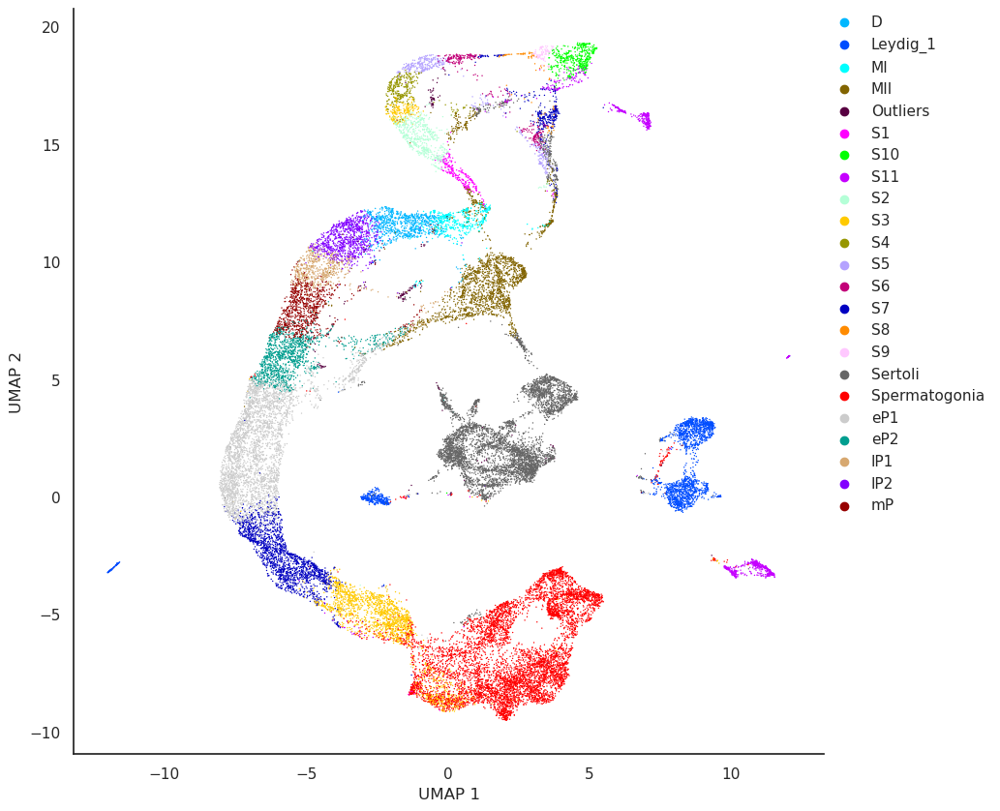

In [7]:
plt.figure(figsize=[10, 10])
plot = sns.scatterplot(x=adata.obsm["X_umap"][:,0], y=adata.obsm["X_umap"][:,1],hue =adata.obs["celltype_scanvi"],palette= categorical_palette[:len(adata.obs["celltype_scanvi"].unique())],marker='.',s=4,linewidth=0)
sns.despine()
legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2');

In [8]:
vae= scvi.model.SCVI.load(save_dir+'/model_batch_gene_zinb_2layer_latent30_adata8',adata)

INFO     File /sas/sara/scRNAseq/pendas//model_batch_gene_zinb_2layer_latent30_adata8/model.pt already downloaded  


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:165: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sara/.local/lib/python3.11/site-packages/ipyke ...
  rank_zero_warn(


In [9]:
adata.layers["normalized_expression"]=vae.get_normalized_expression(adata,library_size=10000)

In [10]:
adata.layers["normalized_expression_log"]=adata.layers["normalized_expression"].copy()
sc.pp.log1p(adata,layer="normalized_expression_log",copy=False)

In [11]:
#sc.pp.scale(adata,layer="normalized_expression_log",copy=False)

In [12]:
pd.DataFrame.sparse.from_spmatrix(adata.X)

,0,1,2,3,4,5,6,7,8,9,...,9521,9522,9523,9524,9525,9526,9527,9528,9529,9530
0,0.0,0.0,0.0,5.0,45.0,0.0,0.0,1.0,0.0,2.0,...,413.0,6.0,2.0,60.0,13.0,0.0,43.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,33.0,0.0,0.0,2.0,0.0,4.0,...,390.0,11.0,2.0,70.0,10.0,0.0,126.0,0.0,0.0,0.0
2,0.0,2.0,0.0,2.0,36.0,0.0,0.0,1.0,0.0,1.0,...,388.0,10.0,5.0,47.0,6.0,0.0,50.0,0.0,0.0,0.0
3,0.0,0.0,1.0,3.0,41.0,0.0,0.0,3.0,0.0,1.0,...,661.0,28.0,3.0,116.0,14.0,2.0,145.0,0.0,0.0,0.0
4,0.0,0.0,0.0,4.0,22.0,0.0,0.0,3.0,0.0,2.0,...,293.0,10.0,2.0,29.0,7.0,0.0,52.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33481,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
33482,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
33483,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
33484,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [13]:
adata.X = adata.layers["normalized_expression_log"]
adata.X

array([[1.5722518e-01, 1.5795940e-01, 8.5531794e-02, ..., 4.5233956e-03,
        1.0529086e-02, 1.7566729e-02],
       [2.2149757e-01, 7.4755818e-02, 1.5665314e-01, ..., 4.8547233e-03,
        1.2880814e-02, 2.8098814e-02],
       [1.4965828e-01, 1.8989597e-01, 1.2445738e-01, ..., 5.7621589e-03,
        1.4966186e-02, 3.7805226e-02],
       ...,
       [2.5536679e-04, 1.6123377e-01, 3.9163262e-01, ..., 4.9519115e-03,
        2.1335091e-02, 5.8325402e-02],
       [4.4549848e-05, 1.9887129e-03, 1.4721467e+00, ..., 5.2684220e-04,
        2.2485607e-05, 8.8953638e-01],
       [6.9078211e-05, 5.9807287e-05, 2.1408067e+00, ..., 1.0563529e-03,
        5.8445841e-04, 6.7675307e-02]], dtype=float32)

In [14]:
adata.X

array([[1.5722518e-01, 1.5795940e-01, 8.5531794e-02, ..., 4.5233956e-03,
        1.0529086e-02, 1.7566729e-02],
       [2.2149757e-01, 7.4755818e-02, 1.5665314e-01, ..., 4.8547233e-03,
        1.2880814e-02, 2.8098814e-02],
       [1.4965828e-01, 1.8989597e-01, 1.2445738e-01, ..., 5.7621589e-03,
        1.4966186e-02, 3.7805226e-02],
       ...,
       [2.5536679e-04, 1.6123377e-01, 3.9163262e-01, ..., 4.9519115e-03,
        2.1335091e-02, 5.8325402e-02],
       [4.4549848e-05, 1.9887129e-03, 1.4721467e+00, ..., 5.2684220e-04,
        2.2485607e-05, 8.8953638e-01],
       [6.9078211e-05, 5.9807287e-05, 2.1408067e+00, ..., 1.0563529e-03,
        5.8445841e-04, 6.7675307e-02]], dtype=float32)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


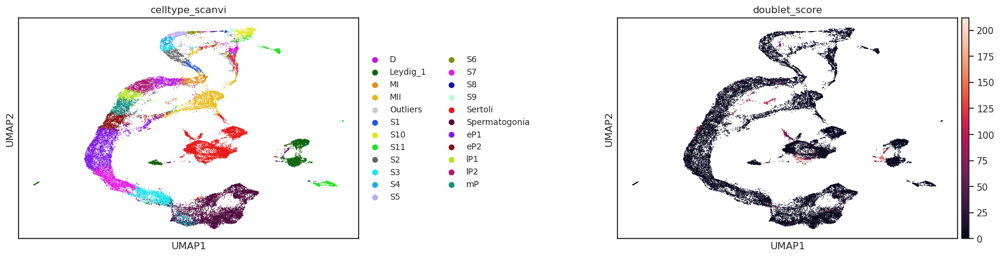

In [15]:
sc.pl.umap(adata, color=["celltype_scanvi","doublet_score"],wspace=0.6,legend_fontsize=10)

In [16]:
adata.obs.columns

Index(['Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts',
       'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb',
       'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts',
       'pct_counts_in_top_20_genes', 'log1p_total_counts_mt',
       'log1p_total_counts_rb', 'doublet', 'doublet_score',
       'doublet_doubletdetection', 'batch', 'Condition', 'type_data',
       'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts',
       'log10_total_features_by_counts', 'log10_total_counts',
       'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features',
       'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features',
       'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels',
       'celltype_scanvi'],
      dtype='object')

In [17]:
adata = adata[adata.obs["doublet_doubletdetection"]=="Singlet"]
adata = adata[~(adata.obs["celltype_scanvi"]=="Outliers")]

adata

View of AnnData object with n_obs × n_vars = 32459 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi'
    var: 'gene_ids-0', 'feature_types-0', 'genome-0', 'mt-0', 'rb-0', 'n_cells-0-0', 'n_cells_by_counts-0-0', 'mean_counts-0-0', 'pct_dropout_by_counts-0-0', 'total_counts-0-0', 'log1p_mean_counts-0-0', 'log1p_total

## Marker annotation

In [8]:
marker_genes = {
    "Spermatogonia_general":["Magea4","Pcna"],
    "Spermatogonial Stem Cells (SSCs)": ["Plzf", "Gfra1","Id4","Pax7","Nano2","Plzf"],
    "Differentiating Spermatogonia": ["Kit","Stra8","Sohlh1","Sohlh2","Lin28","Ngn3"],
    "Spermatocytes (Primary and Secondary)": ["Sycp3","Dmc1","Sycp1", "Sycp2", "Sycp3", "Hormad1", "Hormad2", "Dmc1", "Spo11", "Mlh1", "Tex11","Ccna1","Aurka"],
    "Round Spermatids": ["Tnp1", "Tnp2", "Prm1", "Acr"],
    "Elongating Spermatids":["Prm1", "Prm2","Spaca1", "Izumo1","Odf2","Akap4","Cabyr"],
    "Endothelial cells":["Pecam1","Cdh5","Kdr","Flt1","Tek","Tie1","Vwf","Eng"],
    "PTM":["Acta2","Myh11","Tagln","Des","Cnn1"],
    "Sertoli":["Sox9","Amh","Wt1","Gata4","Nr5a1"],
    "Leydig":["Star","Cyp11a1","Hsd3b1","Hsd3b6","Cyp17a1","Hsd17b3","Insl3"],
    "Macrophagues":["Adgre1","Cd68","Itgam","Csf1r","Lyz2","C1qa","C1qb","Tyrobp","Lgals3","Cd163"],
    "Fibroblasts":["Vim","Pdgfra","Pdgfrb","Col1a1","Col1a2","S100a4","Thy1","Dcn","Itga11","Acta2"]

}

In [9]:
# Este comando comprueba cuantos de esos marcaodres se están expresando en tu dataset.
marker_genes_in_data = dict()
for ct, markers in marker_genes.items():
    markers_found = list()
    for marker in markers:
        if marker in adata.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

marker_genes_in_data

{'Spermatogonia_general': ['Pcna'],
 'Spermatogonial Stem Cells (SSCs)': ['Gfra1', 'Id4'],
 'Differentiating Spermatogonia': ['Kit', 'Stra8', 'Sohlh1', 'Sohlh2'],
 'Spermatocytes (Primary and Secondary)': ['Sycp3',
  'Dmc1',
  'Sycp1',
  'Sycp2',
  'Sycp3',
  'Hormad1',
  'Hormad2',
  'Dmc1',
  'Spo11',
  'Tex11',
  'Ccna1',
  'Aurka'],
 'Round Spermatids': ['Tnp1', 'Acr'],
 'Elongating Spermatids': ['Spaca1', 'Izumo1', 'Odf2', 'Cabyr'],
 'Endothelial cells': ['Pecam1',
  'Cdh5',
  'Kdr',
  'Flt1',
  'Tek',
  'Tie1',
  'Vwf',
  'Eng'],
 'PTM': ['Acta2', 'Myh11', 'Tagln', 'Cnn1'],
 'Sertoli': ['Sox9', 'Wt1', 'Gata4', 'Nr5a1'],
 'Leydig': ['Star', 'Cyp11a1', 'Hsd3b1', 'Cyp17a1', 'Hsd17b3'],
 'Macrophagues': ['Adgre1', 'Cd68', 'Csf1r', 'C1qb', 'Lgals3', 'Cd163'],
 'Fibroblasts': ['Vim',
  'Pdgfra',
  'Col1a1',
  'Col1a2',
  'Thy1',
  'Dcn',
  'Itga11',
  'Acta2']}

In [10]:
marker_genes.keys()

dict_keys(['Spermatogonia_general', 'Spermatogonial Stem Cells (SSCs)', 'Differentiating Spermatogonia', 'Spermatocytes (Primary and Secondary)', 'Round Spermatids', 'Elongating Spermatids', 'Endothelial cells', 'PTM', 'Sertoli', 'Leydig', 'Macrophagues', 'Fibroblasts'])

In [11]:
General = [
'Spermatogonia_general', 'Spermatogonial Stem Cells (SSCs)', 'Differentiating Spermatogonia', 'Spermatocytes (Primary and Secondary)', 'Round Spermatids', 'Elongating Spermatids', 'Endothelial cells', 'PTM', 'Sertoli', 'Leydig',"Macrophagues","Fibroblasts"
    
]

SPERMATOGONIA_GENERAL:


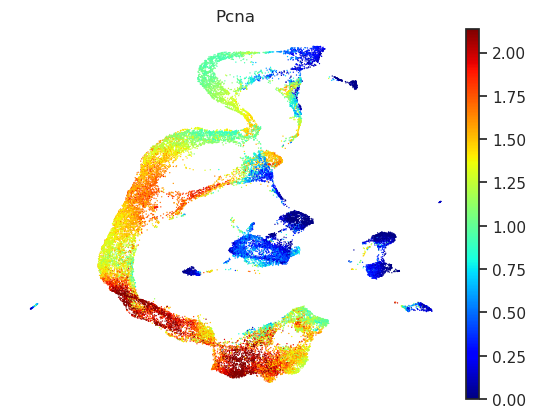





SPERMATOGONIAL STEM CELLS (SSCS):


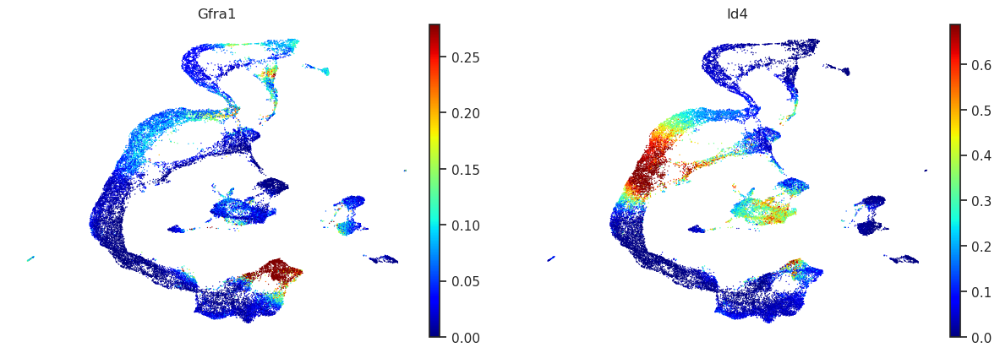





DIFFERENTIATING SPERMATOGONIA:


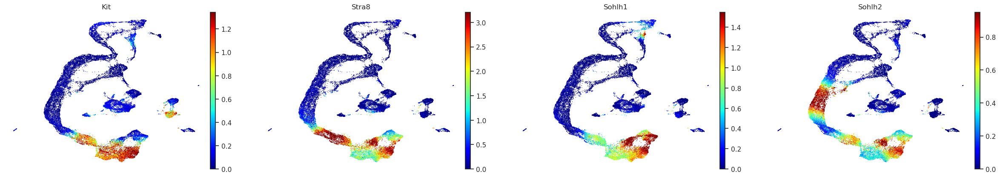





SPERMATOCYTES (PRIMARY AND SECONDARY):


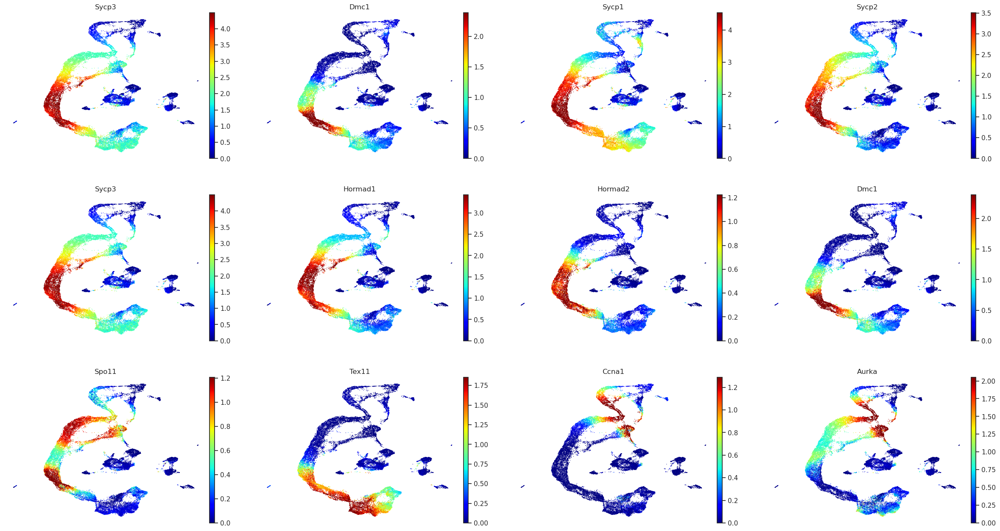





ROUND SPERMATIDS:


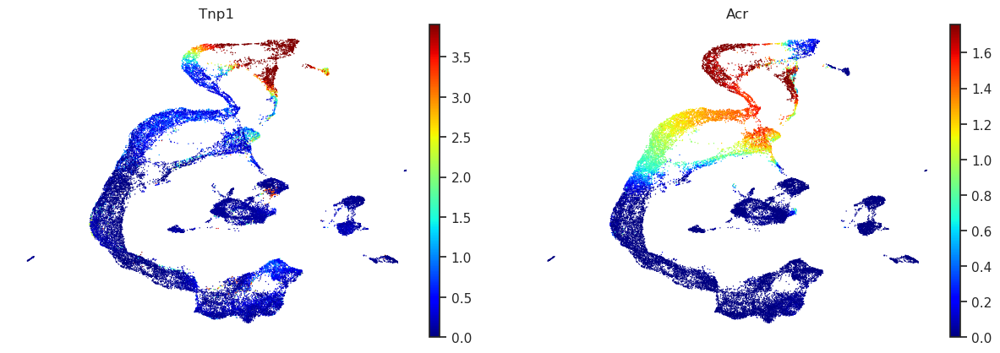





ELONGATING SPERMATIDS:


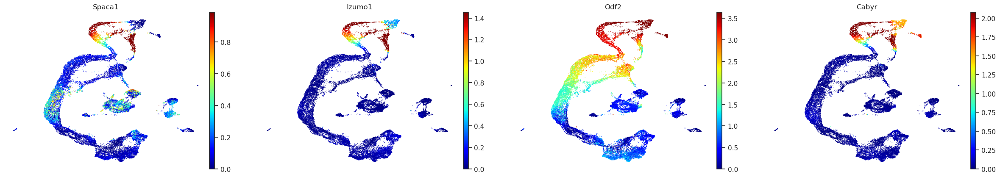





ENDOTHELIAL CELLS:


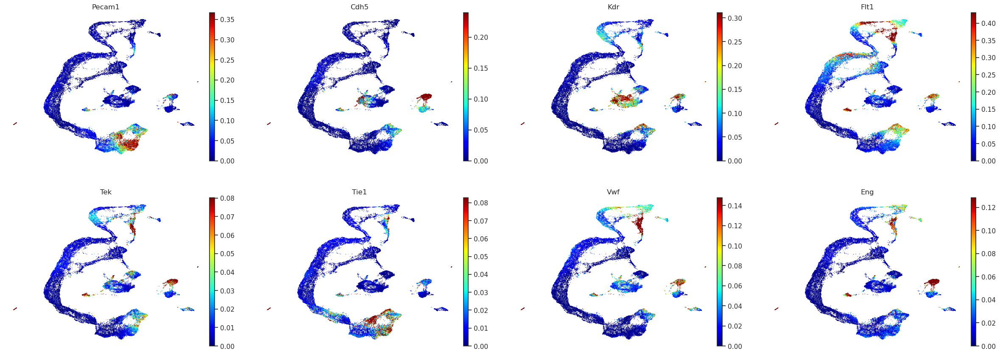





PTM:


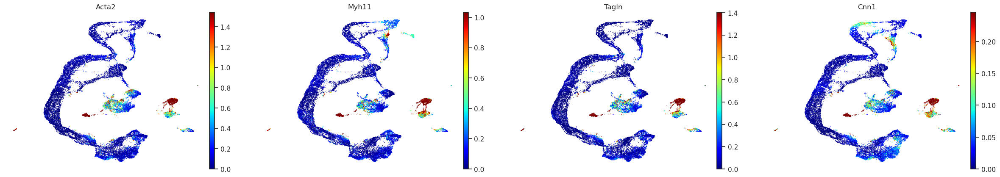





SERTOLI:


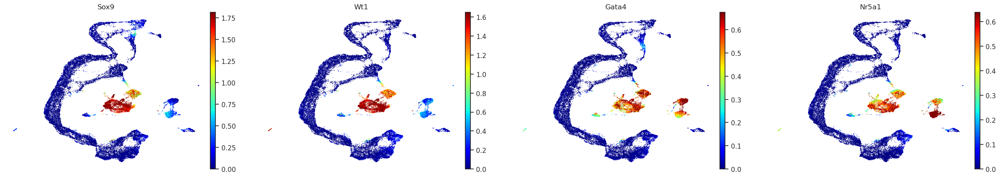





LEYDIG:


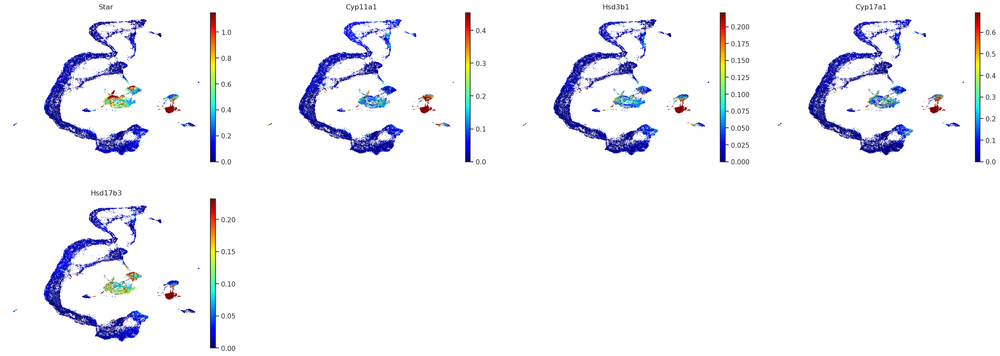





MACROPHAGUES:


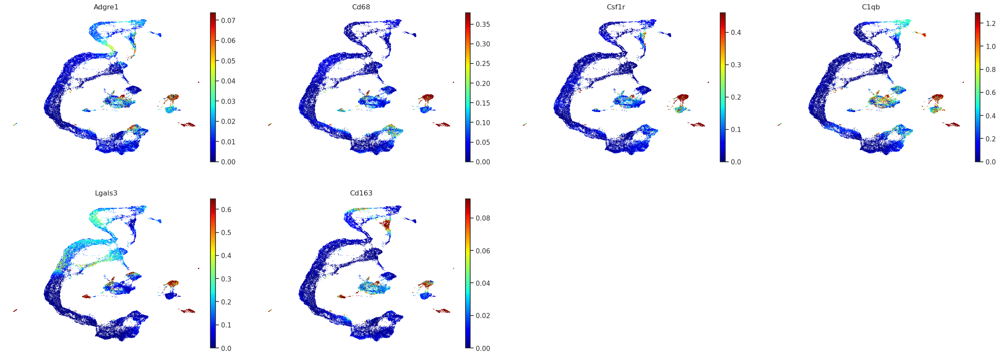





FIBROBLASTS:


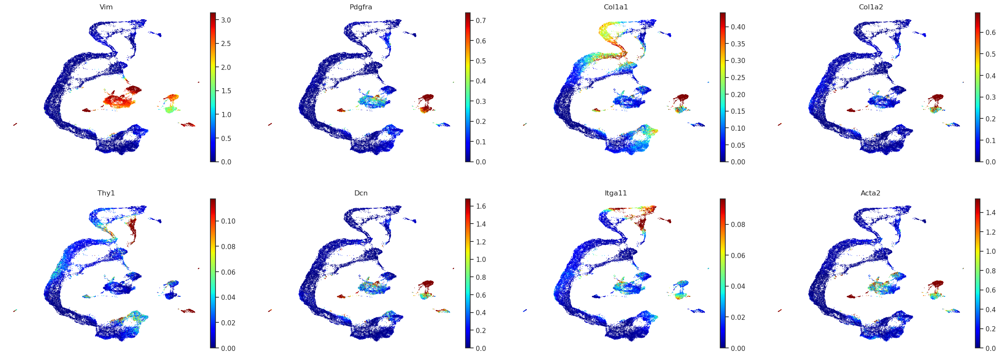

In [22]:
for ct in General:  ## Aquí insertas la lista con las categorías que te interesan. Por ejemplo siquieres ver Tcells cambias General por Tcells.
    print(f"{ct.upper()}:")  # print cell subtype name
    sc.pl.umap(
        adata,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p95",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap=log2_cmap,  
    )
    print("\n\n\n")  

In [23]:
resolutions=[0.2,0.4,0.6,0.8,1,1.2,1.4,1.6]
for value in resolutions:
    sc.tl.leiden(adata,resolution=value,key_added = "leiden_all_"+str(value),neighbors_key="neighbors_model")   ##resolution higher values lead to more clusters.

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_leiden.py:158: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[key_added] = pd.Categorical(


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


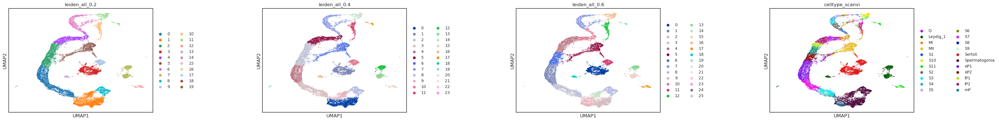

In [24]:
sc.pl.umap(adata, color=["leiden_all_0.2","leiden_all_0.4","leiden_all_0.6","celltype_scanvi"],wspace=0.6,legend_fontsize=10)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


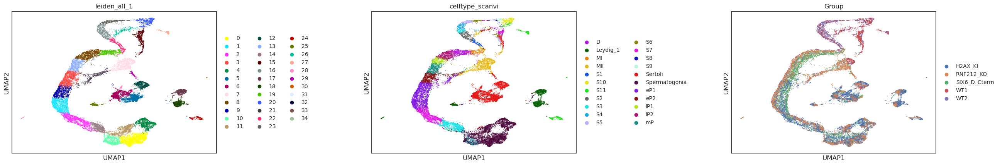

In [25]:
sc.pl.umap(adata, color=["leiden_all_1","celltype_scanvi","Group"],wspace=0.6,legend_fontsize=10)

Text(0.5, 1.0, 'Integration coloured by leiden_0.4')

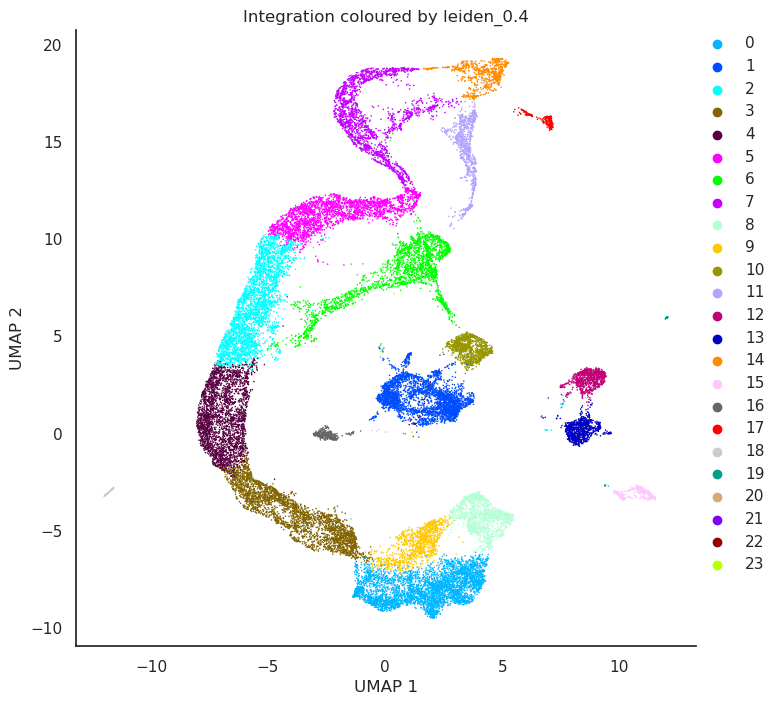

In [26]:
plt.figure(figsize=[8, 8])
sns.set_theme(style="white")
plot = sns.scatterplot(x=adata.obsm["X_umap"][:,0], y=adata.obsm["X_umap"][:,1],hue =adata.obs["leiden_all_0.4"],palette= categorical_palette[:len(adata.obs["leiden_all_0.4"].unique())],marker='.',s=5,linewidth=0)
sns.despine()
legend = plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0., frameon=False)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2');
plt.title("Integration coloured by leiden_0.4")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Figure size 800x800 with 0 Axes>

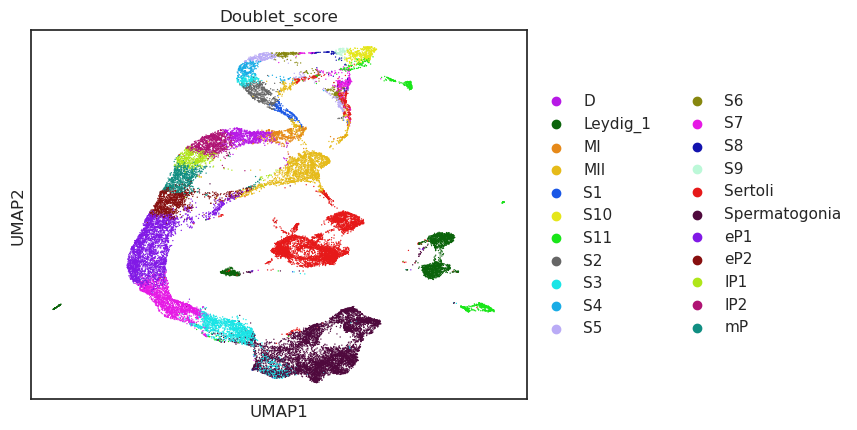

<Figure size 800x800 with 0 Axes>

In [27]:
sc.pl.umap(adata,color="celltype_scanvi",cmap=log2_cmap,show=False,vmax="p99")
plt.title("Doublet_score")
plt.figure(figsize=[8, 8])

<Figure size 800x800 with 0 Axes>

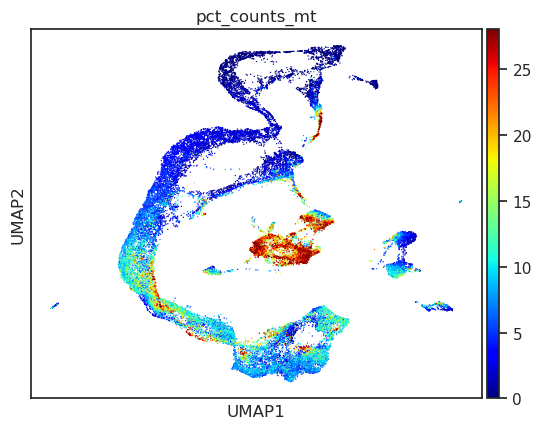

<Figure size 800x800 with 0 Axes>

In [28]:
sc.pl.umap(adata,color="pct_counts_mt",cmap=log2_cmap,show=False,vmax="p99")
plt.figure(figsize=[8, 8])

<Figure size 800x800 with 0 Axes>

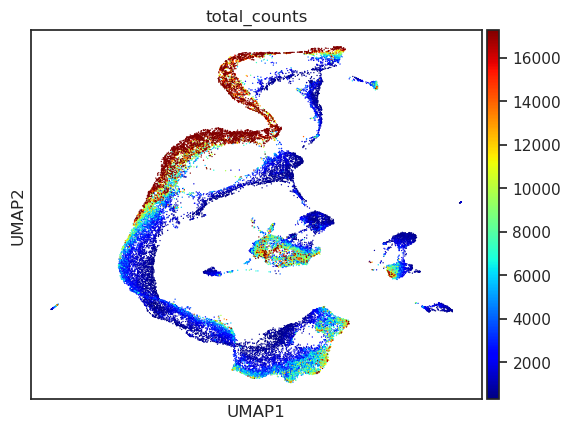

<Figure size 800x800 with 0 Axes>

In [30]:
sc.pl.umap(adata,color="total_counts",cmap=log2_cmap,show=False,vmax="p90")
plt.figure(figsize=[8, 8])

<Figure size 800x800 with 0 Axes>

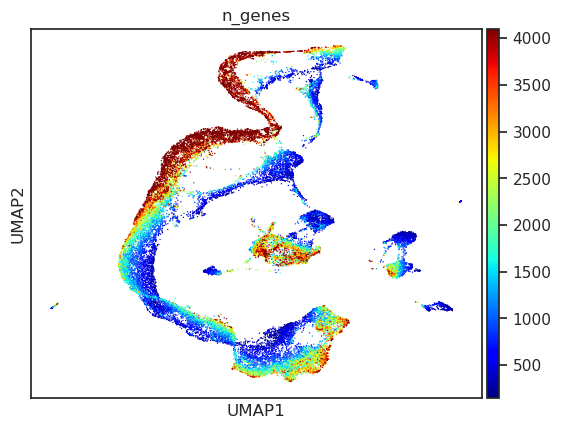

<Figure size 800x800 with 0 Axes>

In [31]:
sc.pl.umap(adata,color="n_genes",cmap=log2_cmap,show=False,vmax="p90")
plt.figure(figsize=[8, 8])

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


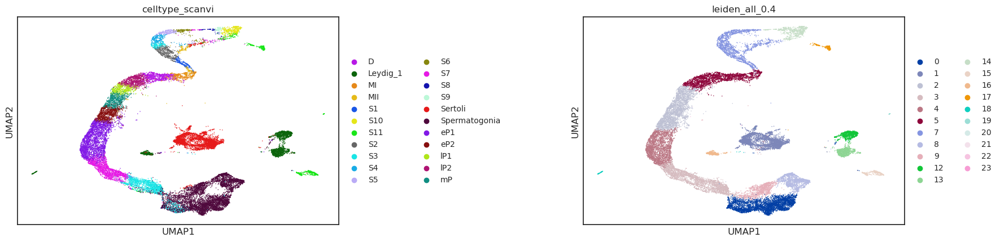

In [32]:
adata= adata[~(adata.obs["leiden_all_0.4"].isin(["6","11","10"]))]


sc.pl.umap(adata, color=["celltype_scanvi","leiden_all_0.4"],wspace=0.6,legend_fontsize=10)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


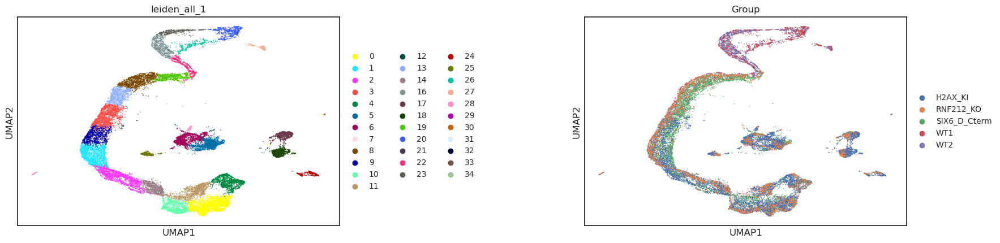

In [34]:
sc.pl.umap(adata, color=["leiden_all_1","Group"],wspace=0.6,legend_fontsize=10)

In [35]:
#adata= adata[~(adata.obs["leiden_all_0.8"].isin(["21"]))]

adata= adata[~(adata.obs["leiden_all_1"].isin(["26"]))]



/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


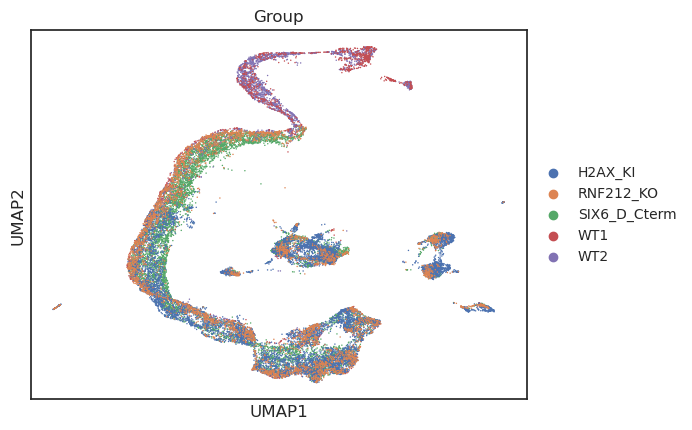

In [36]:
sc.pl.umap(adata, color=["Group"],wspace=0.6,legend_fontsize=10)

In [37]:
sc.pp.neighbors(adata, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(adata, min_dist=0.5,neighbors_key="neighbors_model")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


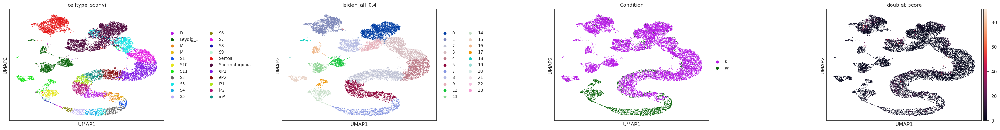

In [38]:
sc.pl.umap(adata, color=["celltype_scanvi","leiden_all_0.4","Condition","doublet_score"],wspace=0.6,legend_fontsize=10)

In [39]:
resolutions=[0.2,0.4,0.6,0.8,1,1.2,1.4,1.6]
for value in resolutions:
    sc.tl.leiden(adata,resolution=value,key_added = "leiden_2_"+str(value),neighbors_key="neighbors_model")   ##resolution higher values lead to more clusters.

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'n_genes'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'pct_counts_rb'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_2_0.6'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_2_0.8'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_2_1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Condition'}, xlabel='UMAP1', ylabel='UMAP2'>]

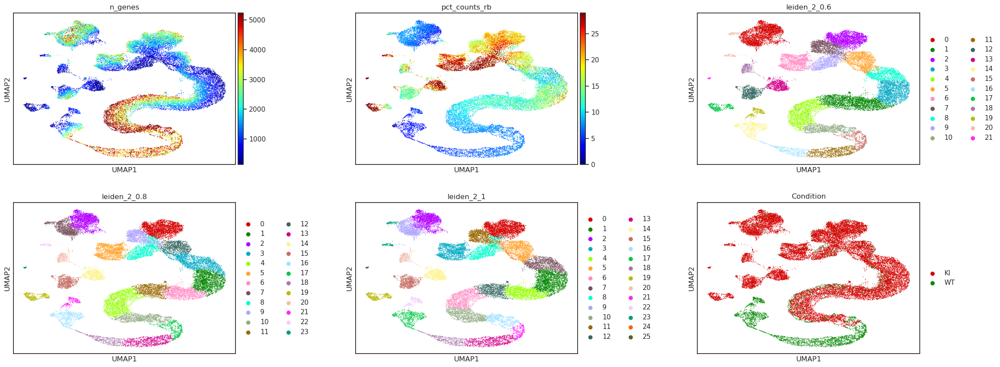

In [40]:
sc.pl.umap(adata,color=["n_genes","pct_counts_rb","leiden_2_0.6","leiden_2_0.8","leiden_2_1","Condition"],cmap=log2_cmap,show=False,vmax="p95",ncols=3,palette=cluster_colors,wspace=0.4)


In [12]:
General_markers = {
    ct: [m for m in ct_markers if m in adata.var.index]
    for ct, ct_markers in marker_genes.items()
    if ct in General
}

In [42]:
adata
level="leiden_2_0.8"

SPERMATOGONIA_GENERAL:


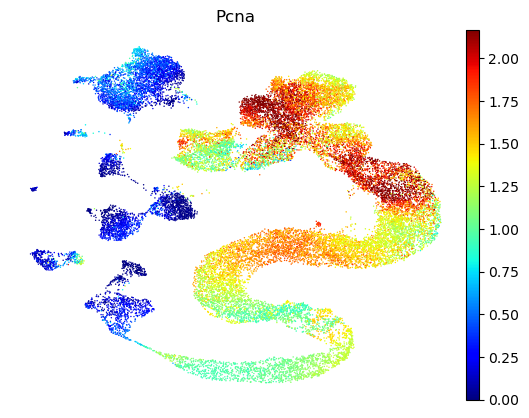





SPERMATOGONIAL STEM CELLS (SSCS):


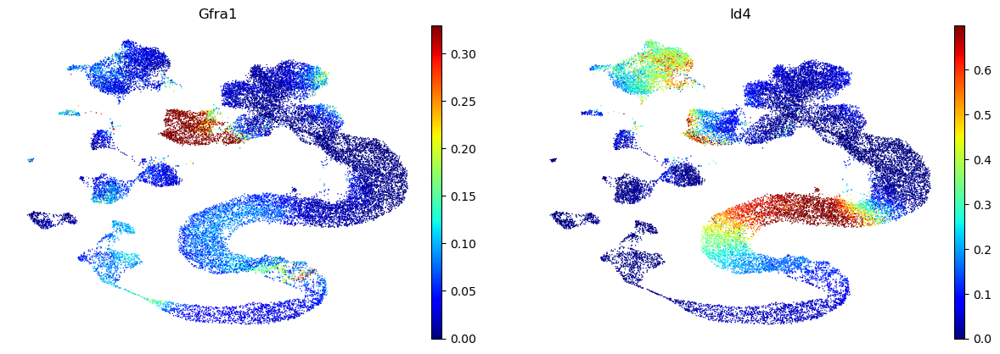





DIFFERENTIATING SPERMATOGONIA:


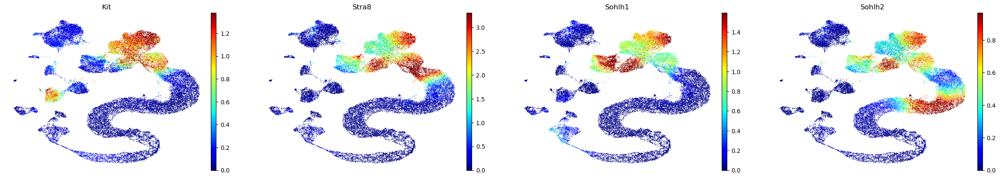





SPERMATOCYTES (PRIMARY AND SECONDARY):


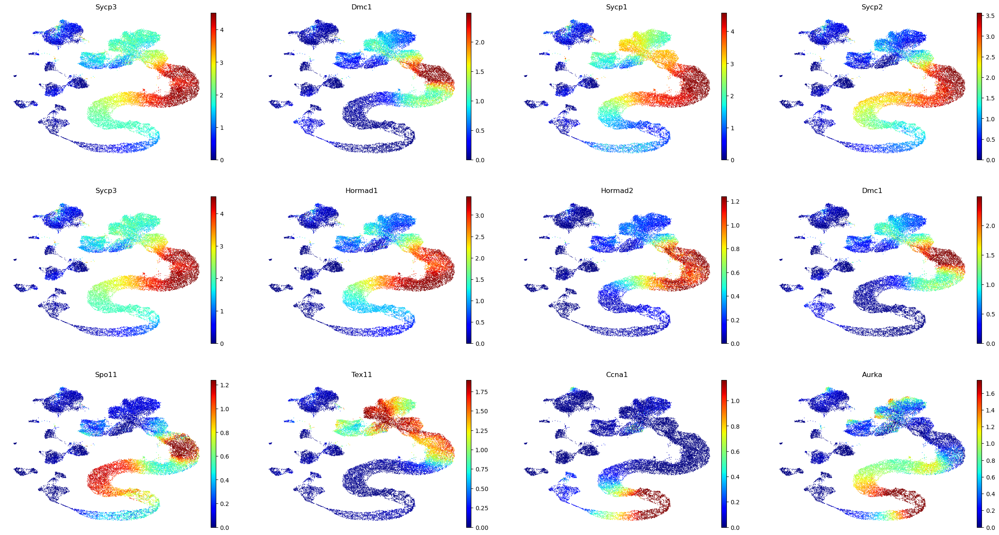





ROUND SPERMATIDS:


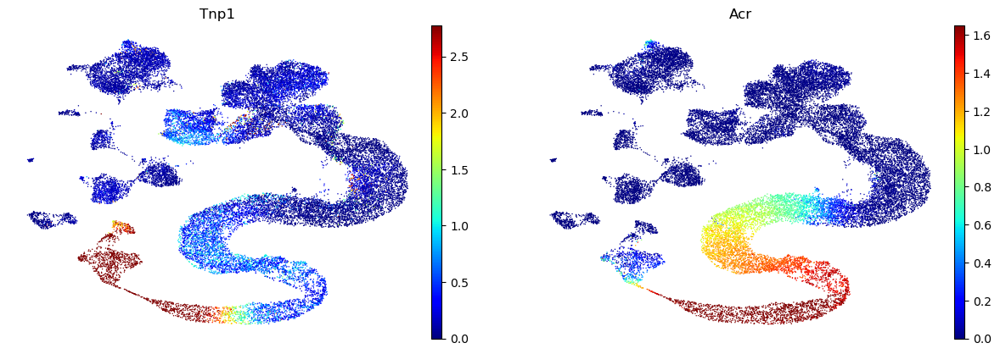





ELONGATING SPERMATIDS:


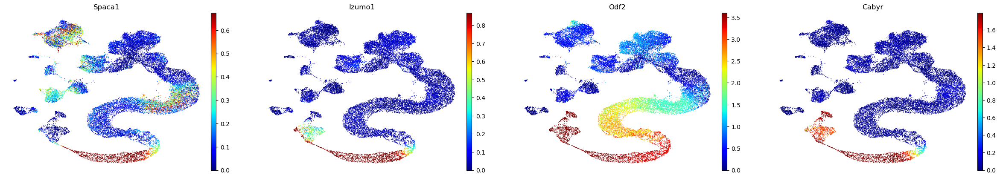





ENDOTHELIAL CELLS:


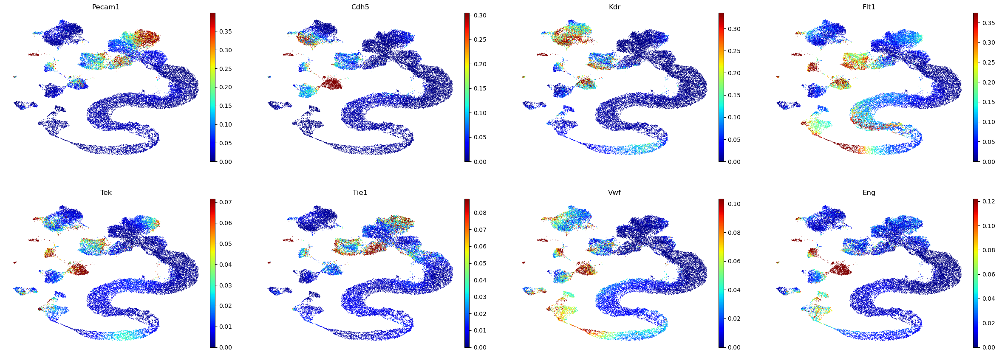





PTM:


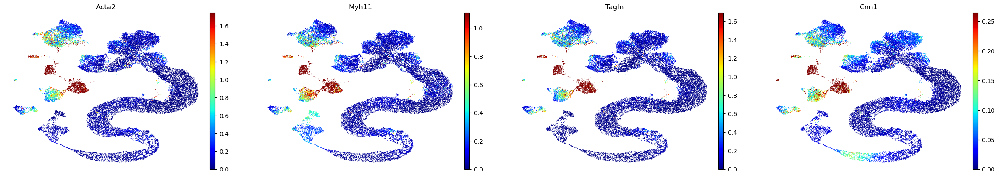





SERTOLI:


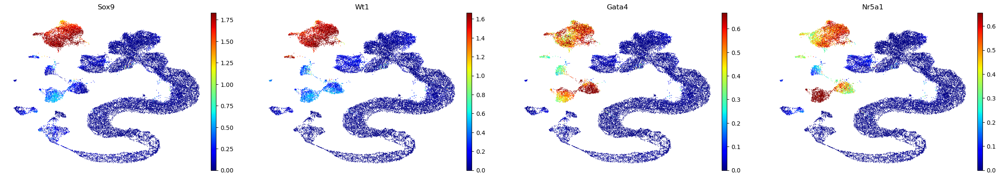





LEYDIG:


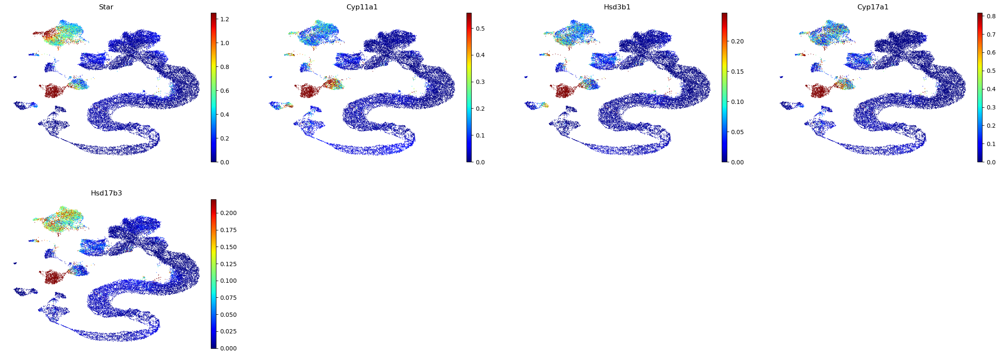





MACROPHAGUES:


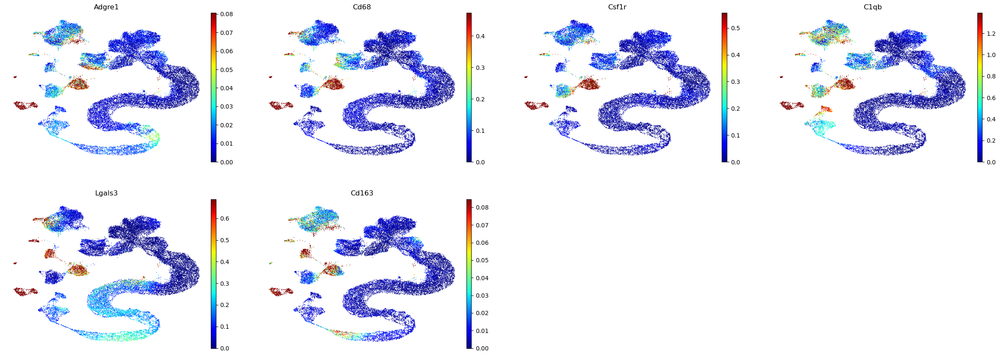





FIBROBLASTS:


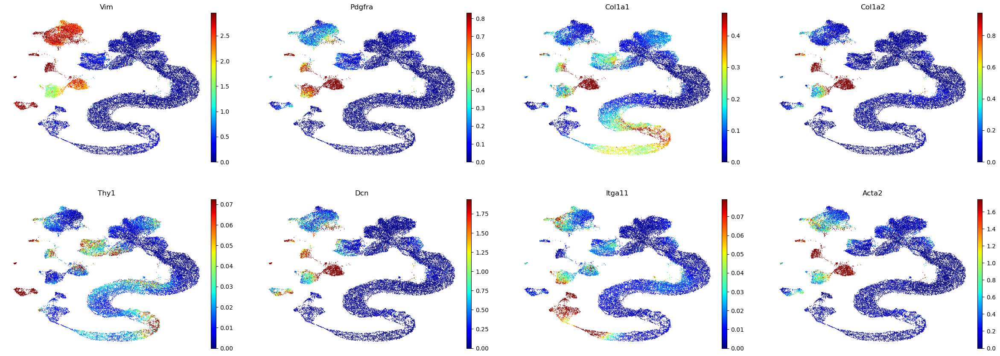

In [52]:
for ct in General:  ## Aquí insertas la lista con las categorías que te interesan. Por ejemplo siquieres ver Tcells cambias General por Tcells.
    print(f"{ct.upper()}:")  # print cell subtype name
    sc.pl.umap(
        adata,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p95",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap=log2_cmap,  
    )
    print("\n\n\n") 

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


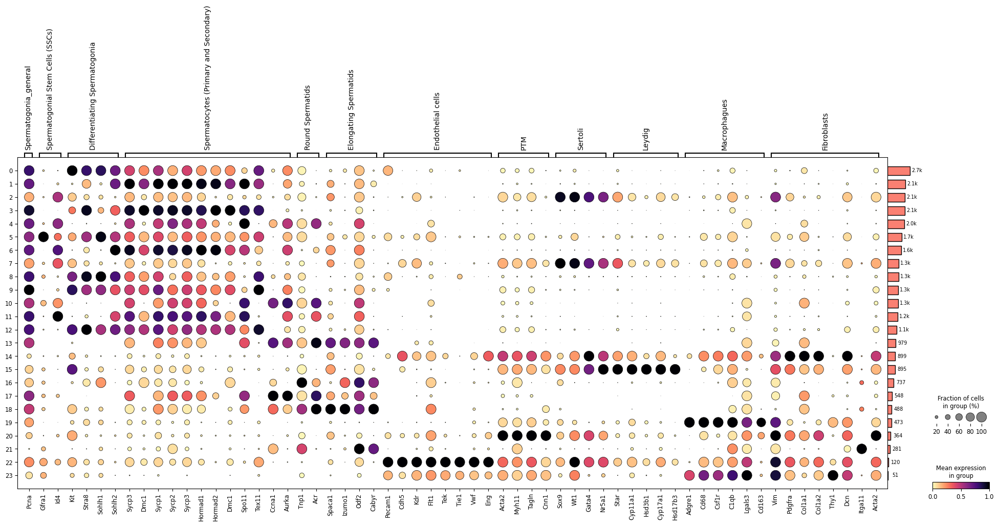

In [43]:
plt.rcdefaults()
dp = sc.pl.dotplot(adata, return_fig=True,cmap="magma_r",standard_scale="var",var_names=General_markers,groupby=level,layer="normalized_expression_log",dendrogram=False,mean_only_expressed=False,expression_cutoff=0.1)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5,cmap="magma_r").show()

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


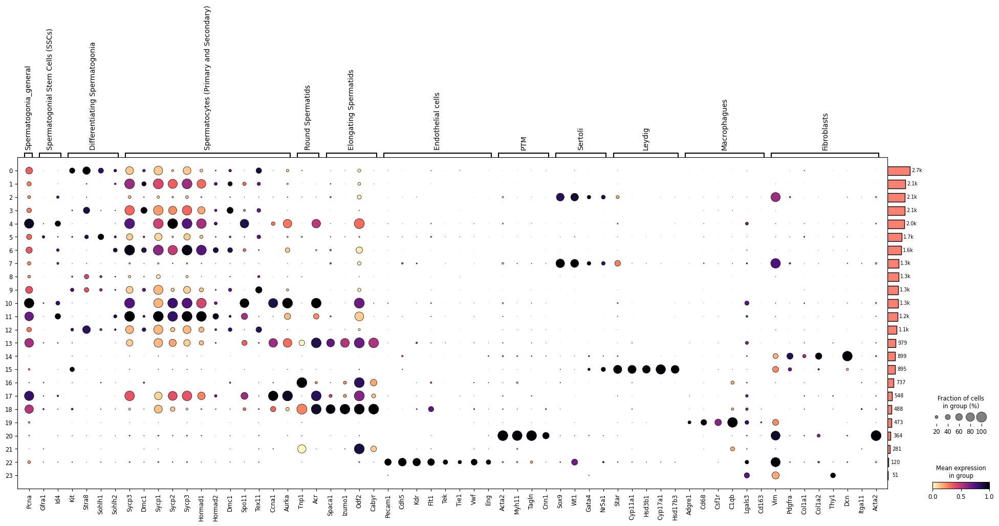

In [44]:
plt.rcdefaults()
dp = sc.pl.dotplot(adata, return_fig=True,cmap="magma_r",standard_scale="var",var_names=General_markers,groupby=level,layer="counts",dendrogram=False,mean_only_expressed=True)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5,cmap="magma_r").show()

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


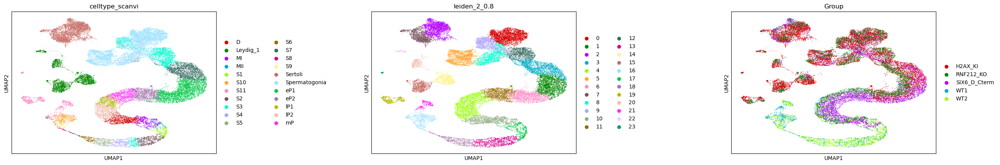

In [51]:
sc.pl.umap(adata, color=["celltype_scanvi",level,"Group"],wspace=0.6,legend_fontsize=10,palette=cluster_colors,vmax="p95")

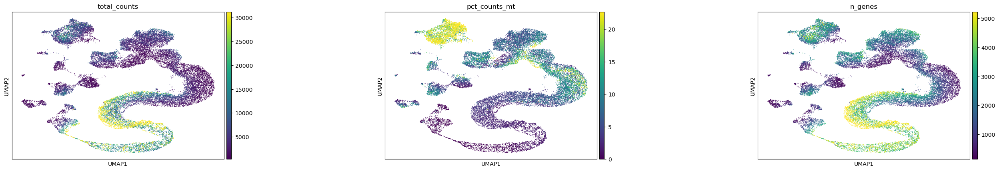

In [ ]:
sc.pl.umap(adata, color=["total_counts","pct_counts_mt","n_genes"],wspace=0.6,legend_fontsize=10,palette=cluster_colors,vmax="p95")

In [ ]:
sc.pl.umap(adata, color=["total_counts","pct_counts_mt","n_genes"],wspace=0.6,legend_fontsize=10,palette=cluster_colors,vmax="p95")

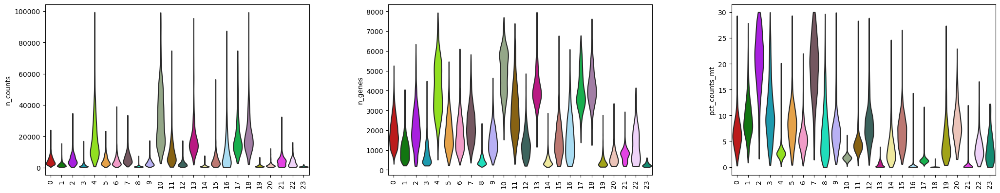

In [47]:
sc.pl.violin(
        adata,
        ["n_counts",'n_genes',"pct_counts_mt"],
        jitter=0.4,
        groupby=level,
        rotation=90,
        stripplot=False,hspace=0.7
    )
    


SPERMATOGONIA_GENERAL:


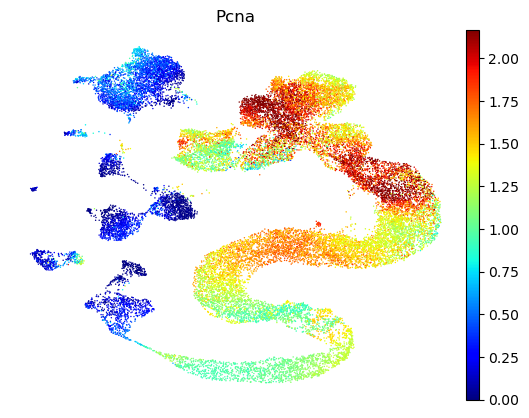





SPERMATOGONIAL STEM CELLS (SSCS):


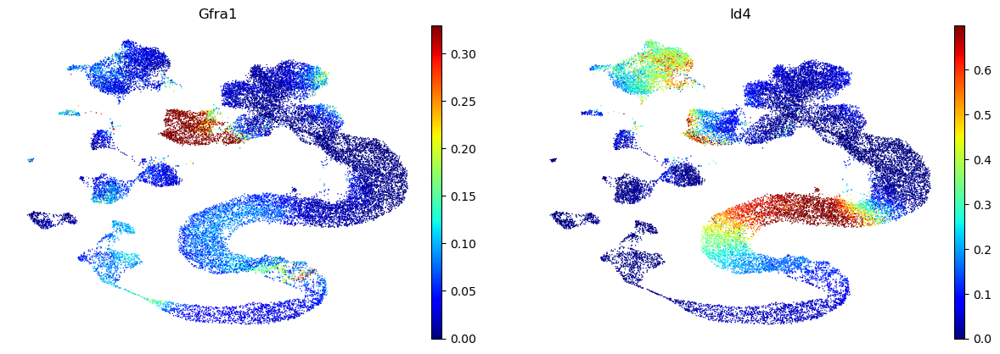





DIFFERENTIATING SPERMATOGONIA:


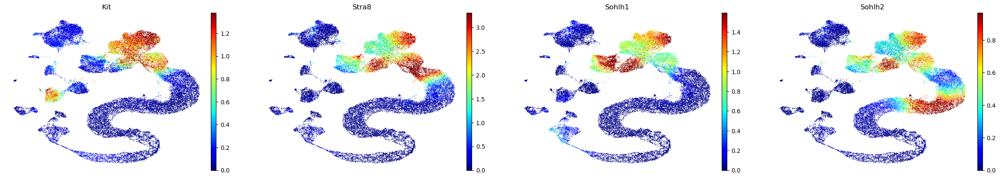





SPERMATOCYTES (PRIMARY AND SECONDARY):


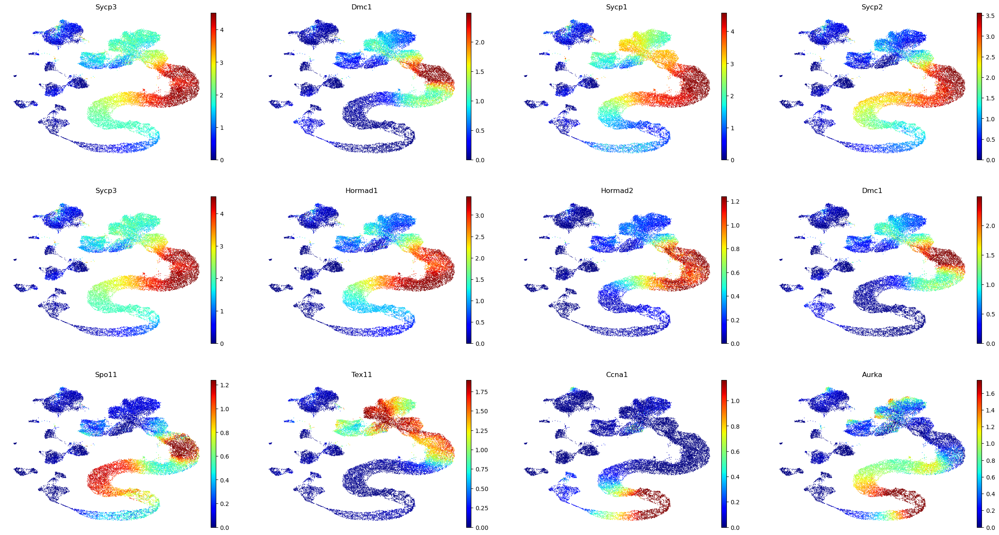





ROUND SPERMATIDS:


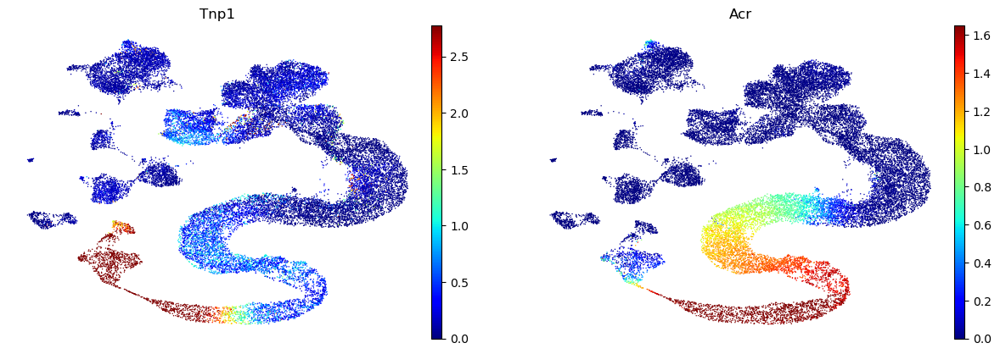





ELONGATING SPERMATIDS:


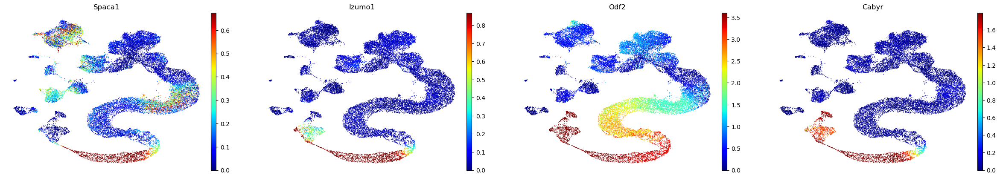





ENDOTHELIAL CELLS:


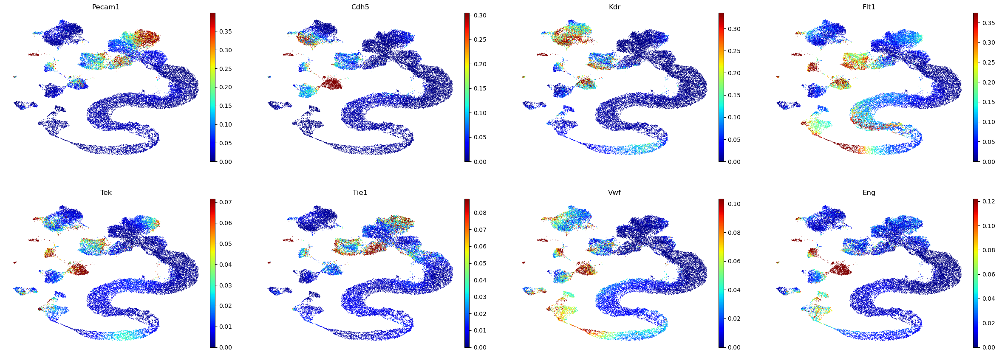





PTM:


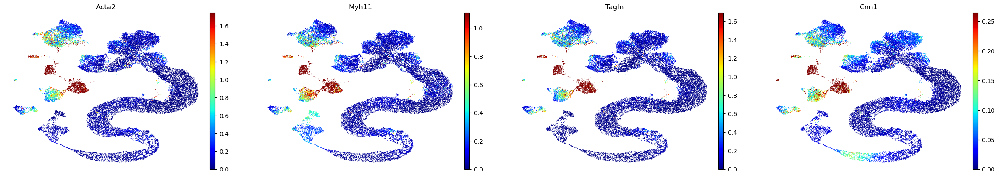





SERTOLI:


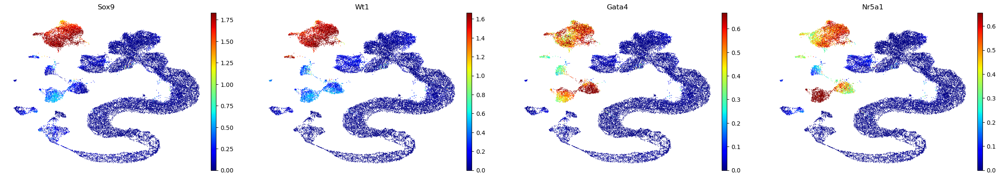





LEYDIG:


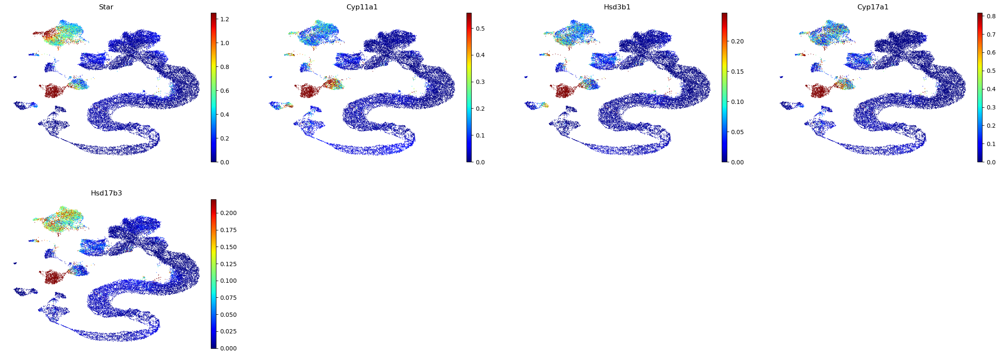





MACROPHAGUES:


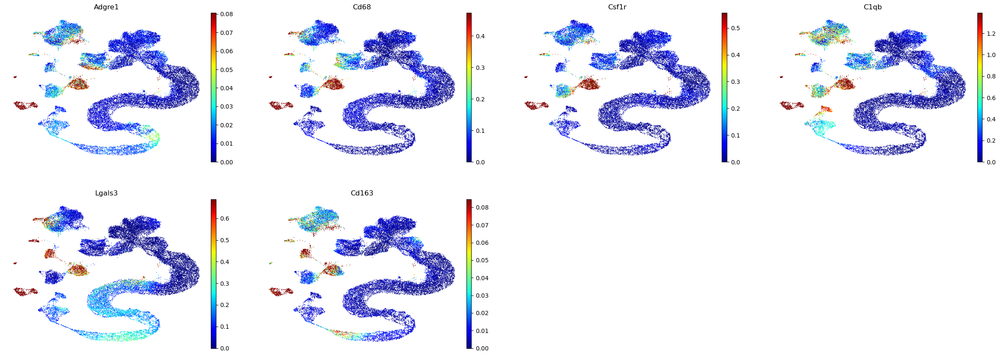





FIBROBLASTS:


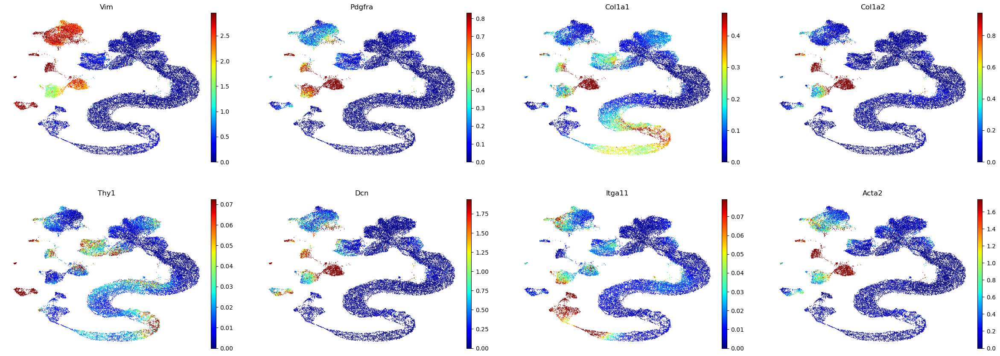

In [48]:
for ct in General:  ## Aquí insertas la lista con las categorías que te interesan. Por ejemplo siquieres ver Tcells cambias General por Tcells.
    print(f"{ct.upper()}:")  # print cell subtype name
    sc.pl.umap(
        adata,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p95",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap=log2_cmap,  
    )
    print("\n\n\n")  

In [49]:
sc.tl.rank_genes_groups(adata, groupby=level)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:396: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'names'] = self.var_names[global_indices]
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:398: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'scores'] = scores[global_indices]
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.

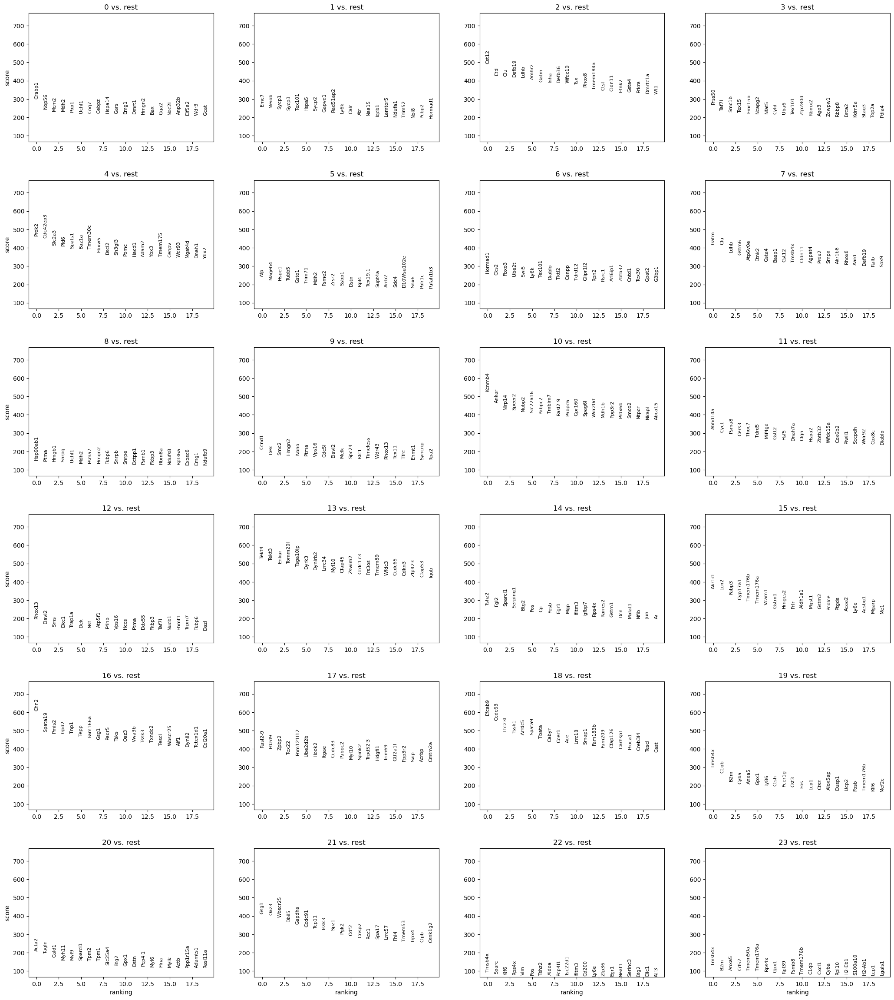

In [50]:
sc.pl.rank_genes_groups(adata)

In [53]:
cluster_map = { "5":"SSCs",
               "0":"Spermatogonia",
               "8":"Spermatogonia",
               "9":"Spermatogonia",
               "12":"Spermatogonia",
               "3":"eP1","1":"eP1",
 "20":"PTM",
 "23":"Remove",
"14":"Fibroblasts",
 "15":"Leydig",
 "2":"Sertoli",
 "19":"Macrophages",
 "22":"Endothelial"
    
}

In [ ]:
# cluster_map = { "8":"SSCs","1":"Spermatogonia","10":"Spermatogonia",
#  "5":"Spermatogonia",
#  "12":"eP1",
#  "6":"eP1",
#  "3":"eP1",
#  "19":"PTM",
#  "14":"Remove",
#  "13":"Remove",
#  "7":"Sertoli",
#  "9":"Sertoli",
#  "23":"Sertoli",
#  "24":"Unknown","25":"Unknown","17":"Macrophages","15":"Leydig","22":"Endothelial"
    
# }

In [54]:
adata.obs["manually_annotation"] = adata.obs["celltype_scanvi"]

adata.obs["manually_annotation"]= adata.obs["leiden_2_0.8"].map(cluster_map).fillna(adata.obs["manually_annotation"])


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'celltype_scanvi'}, xlabel='UMAP1', ylabel='UMAP2'>]

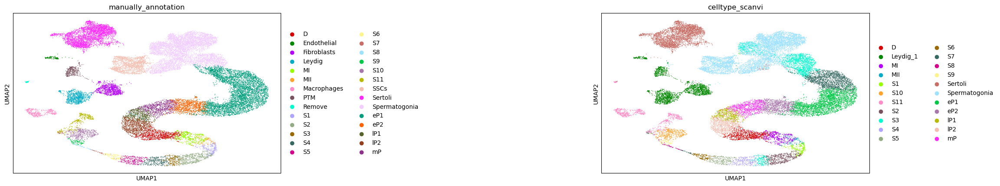

In [55]:
sc.pl.umap(adata,color=["manually_annotation","celltype_scanvi"],cmap=log2_cmap,show=False,vmax="p99",ncols=3,palette=cluster_colors,wspace=1)


In [56]:
legend_info={'D': '#d60000', 'MI': '#05acc6', 'MII': '#97ff00', 'S1': '#79525e', 'S2': '#00fdcf', 'S3': '#afa5ff', 'S4': '#93ac83', 'S5': '#9a6900', 'S6': '#366962', 'S7': '#d3008c', 'S8': '#fdf490', 'S9': '#c86e66', 'S10': '#9ee2ff', 'S11': '#00c846', 'SSCs': '#a877ac', 'Spermatogonia': '#f4bfb1', 'eP1': '#ff28fd', 'eP2': '#f2cdff', 'lP1': '#009e7c', 'lP2': '#ff6200', 'mP': '#56642a'}


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_utils.py:429: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_2_0.8'}, xlabel='UMAP1', ylabel='UMAP2'>]

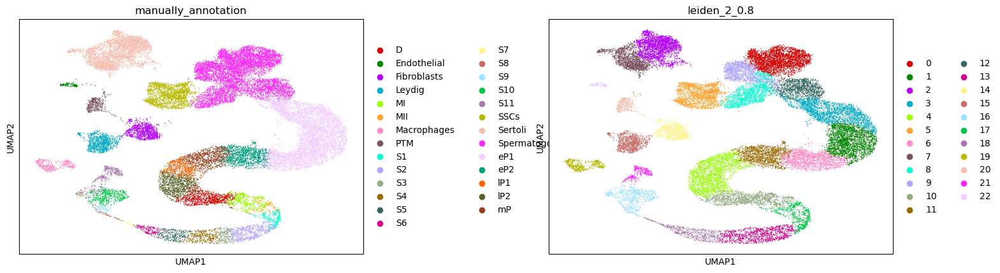

In [59]:
adata= adata[~(adata.obs["manually_annotation"].isin(["Remove"]))]
sc.pl.umap(adata,color=["manually_annotation","leiden_2_0.8"],cmap=log2_cmap,show=False,vmax="p99",ncols=3,palette=cluster_colors,wspace=0.4)


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_S_0.2'}, xlabel='UMAP1', ylabel='UMAP2'>]

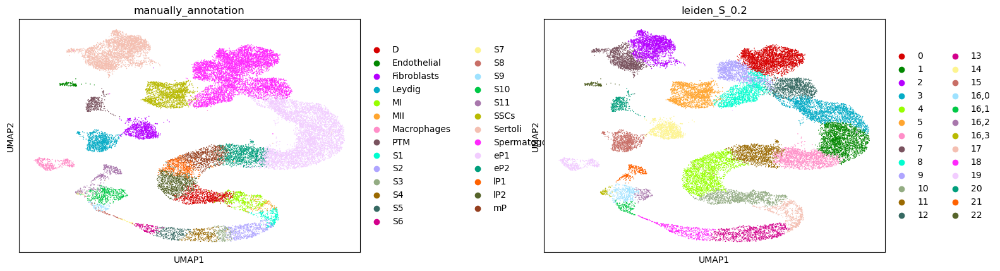

In [60]:
resolutions=[0.1,0.2,0.4,0.6,0.8,1,1.2,1.4]
for value in resolutions:

    sc.tl.leiden(adata,resolution=value,key_added = "leiden_S_"+str(value),neighbors_key="neighbors_model",restrict_to=("leiden_2_0.8",["16"]))   ##resolution higher values lead to more clusters.

    
sc.pl.umap(adata,color=["manually_annotation","leiden_S_0.2"],cmap=log2_cmap,show=False,vmax="p99",ncols=3,palette=cluster_colors,wspace=0.4)

   

In [61]:
sc.tl.rank_genes_groups(adata, groupby="leiden_S_0.2")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:396: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'names'] = self.var_names[global_indices]
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:398: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, 'scores'] = scores[global_indices]
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.

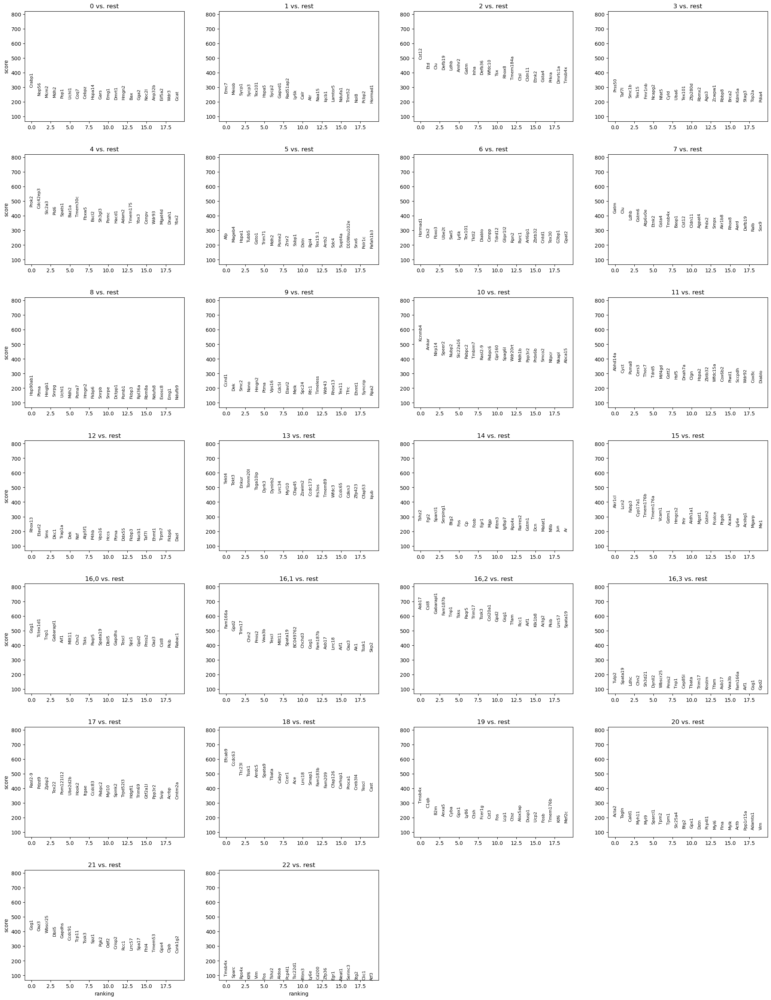

In [62]:
sc.pl.rank_genes_groups(adata)

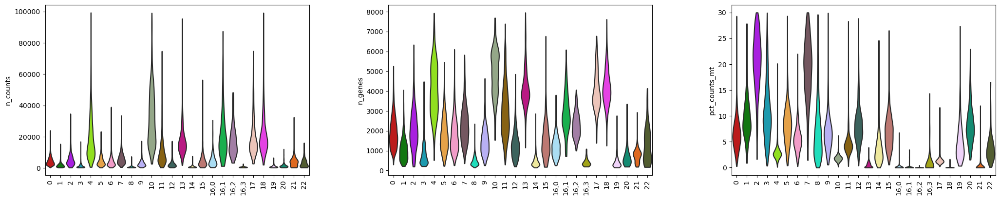

In [64]:
sc.pl.violin(
        adata,
        ["n_counts",'n_genes',"pct_counts_mt"],
        jitter=0.4,
        groupby='leiden_S_0.2',
        rotation=90,
        stripplot=False,hspace=0.7
    )

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


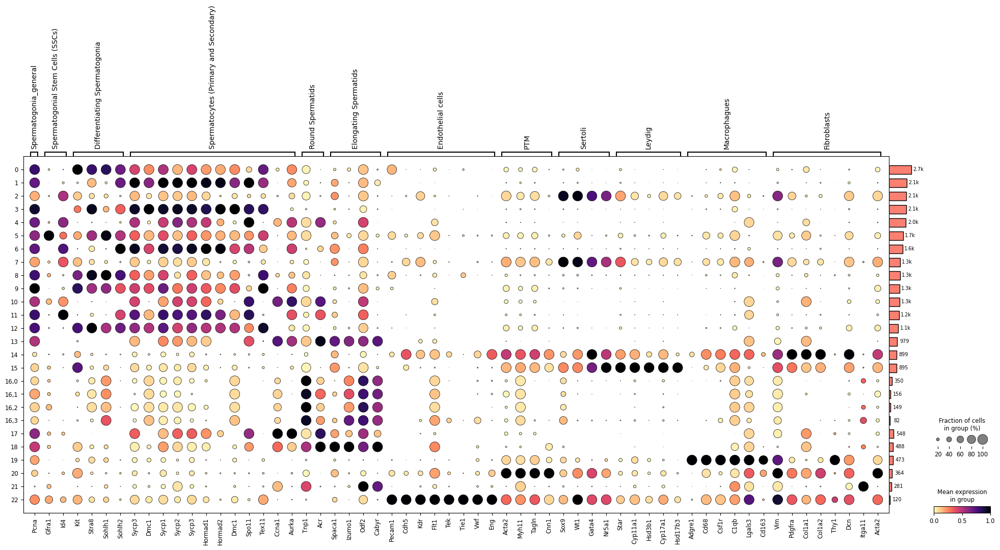

In [65]:
plt.rcdefaults()
dp = sc.pl.dotplot(adata, return_fig=True,cmap="magma_r",standard_scale="var",var_names=General_markers,groupby="leiden_S_0.2",layer="normalized_expression_log",dendrogram=False,mean_only_expressed=False,expression_cutoff=0.1)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5,cmap="magma_r").show()

In [66]:
cluster_map = { 
    "16,0":"S10",
        "16,1":"S10",
    "16,2":"S10",
    "16,3":"S10",

    
}

adata.obs["manually_annotation"]= adata.obs["leiden_S_0.2"].map(cluster_map).fillna(adata.obs["manually_annotation"])

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


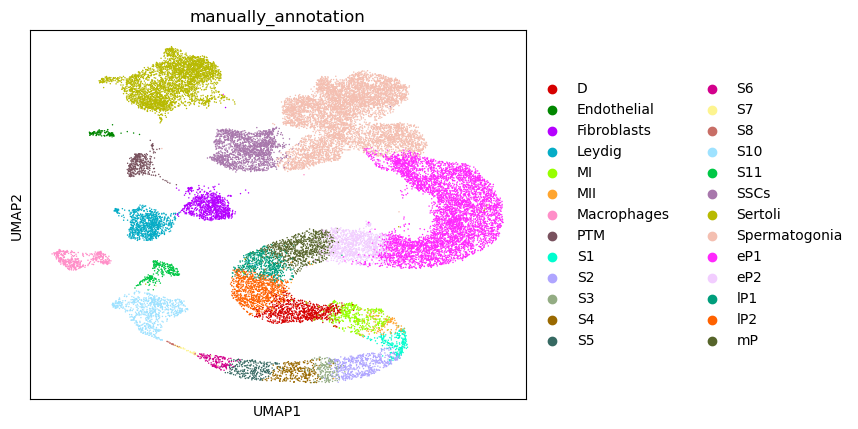

In [67]:
sc.pl.umap(adata,color=["manually_annotation"])

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_utils.py:429: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'leiden_S_0.2'}, xlabel='UMAP1', ylabel='UMAP2'>]

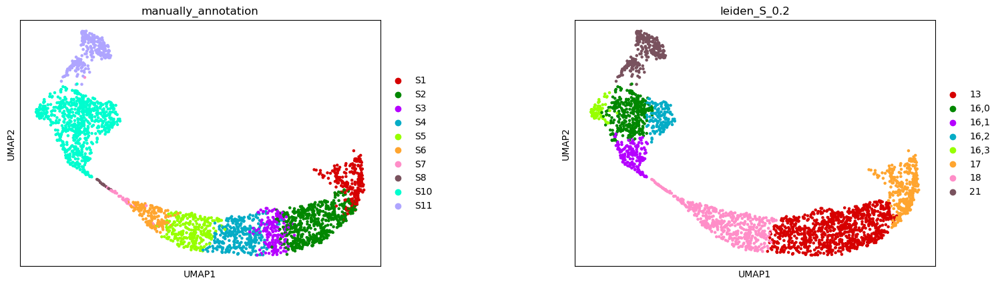

In [68]:
sc.pl.umap(adata[adata.obs["manually_annotation"].isin(["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10","S11"])],color=["manually_annotation","leiden_S_0.2"],cmap=log2_cmap,show=False,vmax="p99",ncols=3,palette=cluster_colors,wspace=0.4)


In [84]:
sc.pp.neighbors(adata, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(adata, min_dist=0.2,neighbors_key="neighbors_model")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>

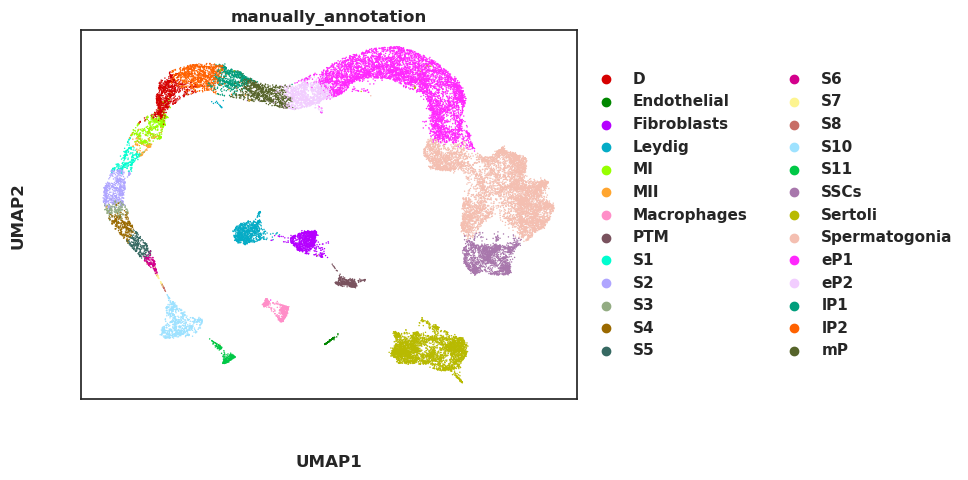

In [85]:
sc.pl.umap(adata,color=["manually_annotation"],cmap=log2_cmap,show=False,vmax="p99",palette=cluster_colors)


/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


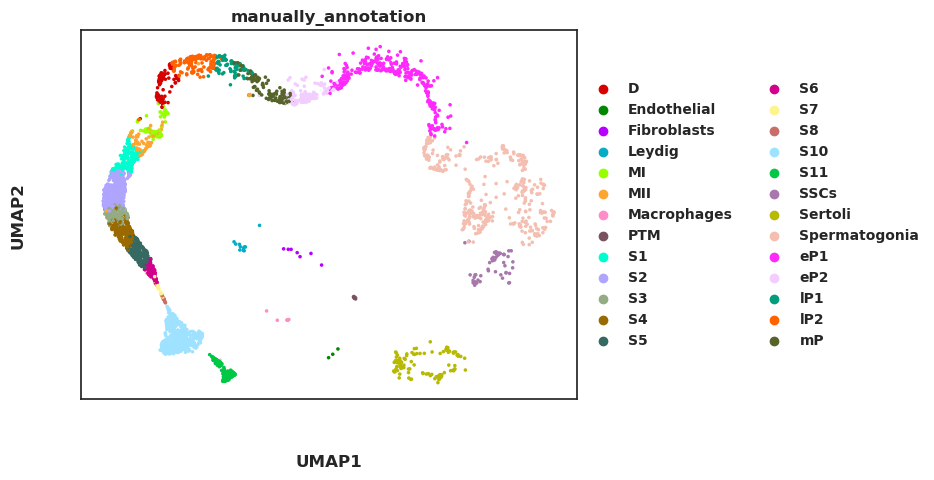

In [86]:
sc.pl.umap(adata[adata.obs["Condition"]=="WT"], color="manually_annotation",wspace=0.6,legend_fontsize=10)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


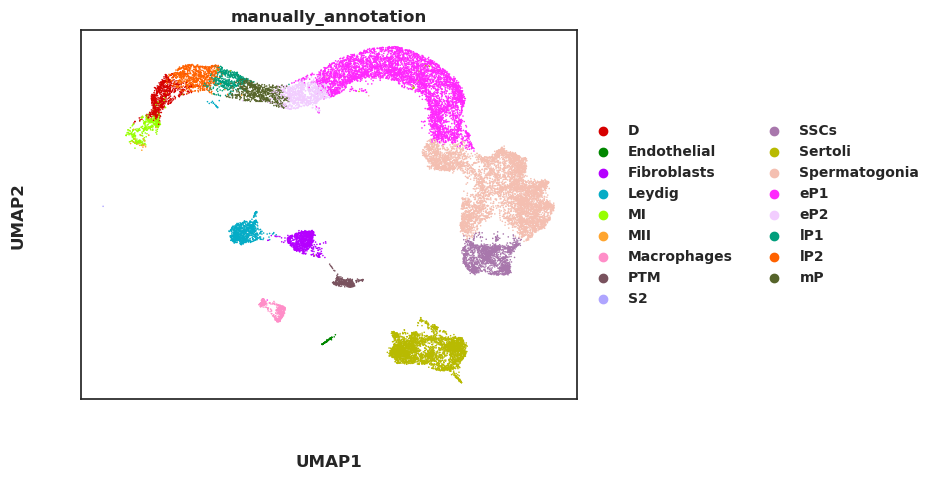

In [87]:
sc.pl.umap(adata[adata.obs["Condition"]=="KI"], color="manually_annotation",wspace=0.6,legend_fontsize=10)

## Definitive dotplot

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


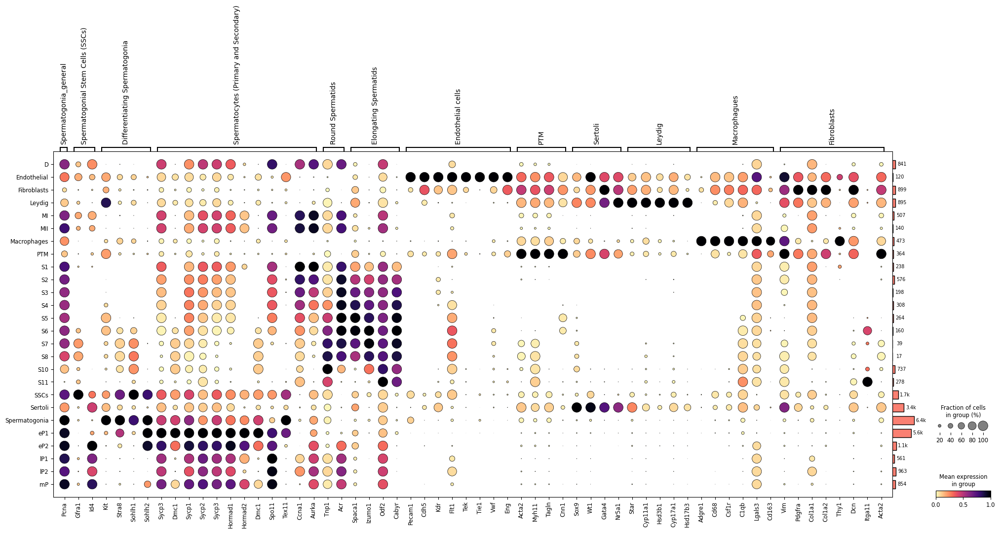

In [13]:
plt.rcdefaults()
dp = sc.pl.dotplot(adata, return_fig=True,cmap="magma_r",standard_scale="var",var_names=General_markers,groupby="manually_annotation",layer="normalized_expression_log",dendrogram=False,mean_only_expressed=False,expression_cutoff=0.1)
dp.add_totals().style(dot_edge_color='black', dot_edge_lw=0.5,cmap="magma_r").show()

In [73]:
### Analysis subpopulations
temp = pd.DataFrame(adata.obs["Group"])
temp["barcodes"] = list(adata.obs.index)
count=temp.groupby(["Group"]).count()
count["Group"]= count.index
count

,barcodes,Group
Group,,
H2AX_KI,9981,H2AX_KI
RNF212_KO,4511,RNF212_KO
SIX6_D_Cterm,8666,SIX6_D_Cterm
WT1,1381,WT1
WT2,3119,WT2


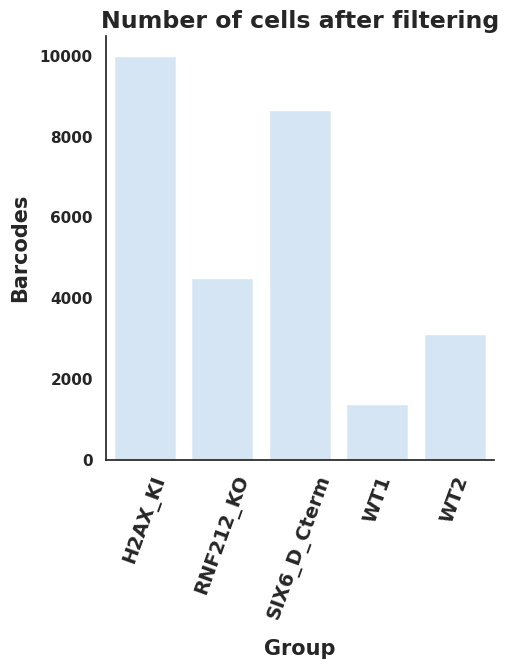

In [74]:
plt.rcdefaults()
sns.set_theme(style="white")
plt.rcParams.update({"axes.labelpad":40,"axes.labelweight":"bold","axes.titleweight":"bold",'font.size': 13, "font.weight":"bold"})

plt.figure(figsize=[5, 5.5])
sns.barplot(data=count, x="Group", y="barcodes",color="#D1E5F8")
plt.xticks(rotation=70,size=14)
plt.ylabel("Barcodes",labelpad=7,size=15)
plt.xlabel("Group",labelpad=12,size=15)
plt.title("Number of cells after filtering",weight="bold",size=17)
sns.despine()



In [75]:
adata.obs["manually_annotation"] = adata.obs["manually_annotation"].str.replace("Leydig_1","Leydig")

In [ ]:
save_dir='/sas/sara/scRNAseq/pendas/'

adata.write_h5ad(save_dir+"adata_reannotated4.h5ad")

In [6]:
adata = sc.read_h5ad(save_dir+"adata_reannotated4.h5ad")

In [78]:
remap_leiden={
"Fibroblasts":"Support",
"SSCs":"Spermato",
"MI":"Spermato",
"lP2":"Spermato",
"D":"Spermato",
"lP1":"Spermato",
"eP2":"Spermato",
"mP":"Spermato",
"Sertoli":"Support",
"MII":"Spermato",
"Leydig":"Support",
"eP1":"Spermato",
"Spermatogonia":"Spermato",
"Endothelial_cells":"Spermato",
"PTM":"Support",
"Macrophagues":"Support",
"Endothelial":"Support",
"S5":"Spermato",
"S4":"Spermato",
"S7":"Spermato",
"S1":"Spermato",
"S2":"Spermato",
"S6":"Spermato",
"S10":"Spermato",
"S8":"Spermato",
"S9":"Spermato",
"S3":"Spermato",
"S11":"Spermato"}

adata.obs["manually_level1"] = adata.obs["manually_annotation"]
adata.obs["manually_level1"]  = adata.obs["manually_level1"].map(remap_leiden).astype('category')
adata.obs

,Sample,Group,n_genes,n_counts,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rb,pct_counts_rb,...,manually_annotation,leiden_S_0.1,leiden_S_0.2,leiden_S_0.4,leiden_S_0.6,leiden_S_0.8,leiden_S_1,leiden_S_1.2,leiden_S_1.4,manually_level1
ACACGCGCATAGAGGC-1-0-0,SI-TT-A1,SIX6_D_Cterm,7075.0,88695.0,7064.0,88695,1746.0,1.968544,6467.0,7.291279,...,MI,10,10,10,10,10,10,10,10,Spermato
TGGGAGACAGTTGGTT-1-0-0,SI-TT-A1,SIX6_D_Cterm,6812.0,70090.0,6807.0,70090,1430.0,2.040234,5066.0,7.227850,...,MI,10,10,10,10,10,10,10,10,Spermato
CACACAACATGGAGAC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6892.0,68932.0,6885.0,68932,2420.0,3.510706,6916.0,10.033076,...,lP2,4,4,4,4,4,4,4,4,Spermato
GAAATGAAGCCTCCAG-1-0-0,SI-TT-A1,SIX6_D_Cterm,6416.0,58599.0,6410.0,58599,1323.0,2.257718,4214.0,7.191249,...,D,10,10,10,10,10,10,10,10,Spermato
TGATTCTAGCCTCTTC-1-0-0,SI-TT-A1,SIX6_D_Cterm,6418.0,57103.0,6407.0,57103,1152.0,2.017407,4287.0,7.507486,...,D,10,10,10,10,10,10,10,10,Spermato
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACATTTCTCGCCAGTG-1-4-0,SI-TT-H12,RNF212_KO,208.0,323.0,208.0,323,15.0,4.643963,159.0,49.226006,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato
GAAACCTCACCTGCAG-1-4-0,SI-TT-H12,RNF212_KO,288.0,373.0,288.0,373,8.0,2.144772,106.0,28.418231,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato
AAGTCGTAGGTGTGAC-1-4-0,SI-TT-H12,RNF212_KO,226.0,324.0,226.0,324,8.0,2.469136,90.0,27.777778,...,Fibroblasts,14,14,14,14,14,14,14,14,Support
AGTAGTCTCTGGTCAA-1-4-0,SI-TT-H12,RNF212_KO,221.0,328.0,221.0,328,7.0,2.134146,152.0,46.341463,...,Spermatogonia,8,8,8,8,8,8,8,8,Spermato


In [79]:
reduced_adata = adata[adata.obs["manually_level1"]=="Spermato"]

In [80]:
reduced_adata

View of AnnData object with n_obs × n_vars = 21473 × 9531
    obs: 'Sample', 'Group', 'n_genes', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'log1p_total_counts_rb', 'doublet', 'doublet_score', 'doublet_doubletdetection', 'batch', 'Condition', 'type_data', 'Barcode', 'Library', 'is_cell_control', 'total_features_by_counts', 'log10_total_features_by_counts', 'log10_total_counts', 'pct_counts_in_top_50_features', 'pct_counts_in_top_100_features', 'pct_counts_in_top_200_features', 'pct_counts_in_top_500_features', 'BroadClusters', 'AnnotatedClusters', '_scvi_batch', '_scvi_labels', 'celltype_scanvi', 'leiden_all_0.2', 'leiden_all_0.4', 'leiden_all_0.6', 'leiden_all_0.8', 'leiden_all_1', 'leiden_all_1.2', 'leiden_all_1.4', 'leiden_all_1.6', 'leiden_2_0.2', 'leiden_2_0.4', 'leiden_2_0.6', 'leiden_2_0.8', 'leiden_

In [81]:
sc.pp.neighbors(reduced_adata, use_rep="X_scVI",key_added="neighbors_model")
sc.tl.umap(reduced_adata, min_dist=0.1,neighbors_key="neighbors_model")

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Kit'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Stra8'}, xlabel='UMAP1', ylabel='UMAP2'>]

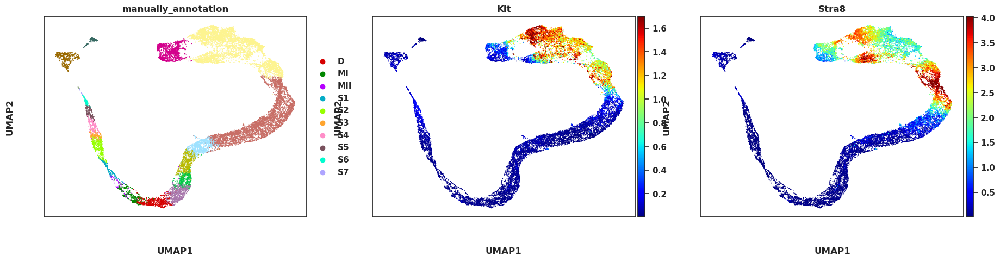

In [82]:
sc.pl.umap(reduced_adata,color=["manually_annotation","Kit","Stra8"],cmap=log2_cmap,show=False,vmax="p99",palette=cluster_colors)

/data/programs/mambaforge/envs/cansada1/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


[<Axes: title={'center': 'Sycp3'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Sycp1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Spo11'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'Hormad1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'manually_annotation'}, xlabel='UMAP1', ylabel='UMAP2'>]

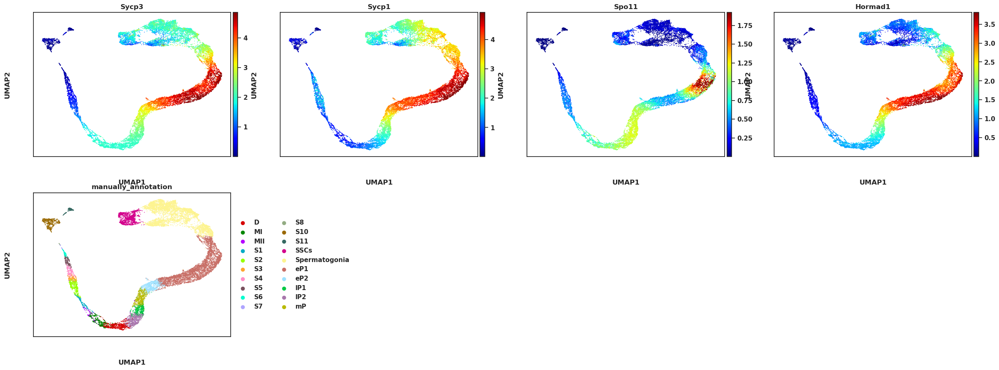

In [83]:
sc.pl.umap(reduced_adata,color=["Sycp3","Sycp1","Spo11","Hormad1","manually_annotation"],cmap=log2_cmap,show=False,vmax="p99",palette=cluster_colors)